# Árvore de decisão V3 com sobreamostragem aleatória
A V3 estima, no momento da coleta pela transportadora, o risco de atraso na entrega. Use em csv_path a mesma tabela utilizada na V1 e execute as células em ordem. A classe 1 representa atraso.
Etapa	Pedidos elegíveis	Uso da sobreamostragem
Ajuste	Coleta e entrega ao cliente anteriores a 01/05/2018	Uma amostra fixa para as 50 tentativas do Optuna e para a curva de poda
Validação	Coleta em maio ou junho de 2018	Todos os pedidos para escolher parâmetros e limiar
Reajuste final	Ajuste e validação reunidos	Nova amostra após congelar parâmetros e limiar
Teste	Coleta a partir de 01/07/2018	Todos os pedidos para avaliar a configuração escolhida


O RandomOverSampler preserva todos os pedidos de treino e repete pedidos da classe minoritária, com reposição, até igualar as contagens das duas classes. A árvore usa class_weight=None. As proporções aprendidas nas folhas refletem esse treino balanceado. O limiar é escolhido na distribuição natural da validação.

O notebook gera o modelo arvore_decisao_lastmile_oversampling_model.pkl e grava os diagnósticos em resultados_arvore_v3/.


In [11]:
# Celula 1: prepara o ambiente de trabalho para toda a analise.
# - pandas/numpy: manipulacao de dados
# - matplotlib: graficos
# - scikit-learn: treino, validacao e metricas
# - DecisionTreeClassifier: modelo de classificacao
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from IPython.display import display
from sklearn.metrics import confusion_matrix
import sklearn


from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    fbeta_score,
    roc_auc_score,
    average_precision_score,
    balanced_accuracy_score,
    matthews_corrcoef,
    brier_score_loss,
    log_loss,
    ConfusionMatrixDisplay,
)

from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import classification_report

# Instala automaticamente o optuna apenas se ele nao estiver disponivel.
try:
    import optuna
except ImportError:
    import sys
    import subprocess
    subprocess.check_call([sys.executable, "-m", "pip", "install", "optuna", "-q"])
    import optuna

try:
    import imblearn
except ModuleNotFoundError as erro:
    if erro.name != "imblearn":
        raise
    import subprocess
    import sys
    subprocess.check_call([sys.executable, "-m", "pip", "install", "imbalanced-learn", "-q"])
    import imblearn
from imblearn.over_sampling import RandomOverSampler

# Mostra todas as colunas ao inspecionar DataFrames.
pd.set_option("display.max_columns", None)
print("Bibliotecas carregadas com sucesso.")
# Convenção visual compartilhada pelos novos diagnósticos.
CORES = {"f1": "#1F4E79", "precision": "#B86F52", "recall": "#557A46"}
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False})

Bibliotecas carregadas com sucesso.


In [12]:
# Celula 2: leitura da base e preparo das variaveis de entrada.
csv_path = Path("../../tabela_final/table_orders_holidays_ecommerce_events.csv")
# "v1" lê os atributos prontos. "legado_v3" reproduz as fórmulas do CSV antigo.
formato_entrada = "v1"
df = pd.read_csv(csv_path)

target_col = "delivered_on_time"
if target_col not in df.columns:
    raise ValueError(f"A coluna alvo '{target_col}' nao foi encontrada no CSV.")

# =====================================================================
# 1. ENGENHARIA DO SLA (Prazo da Transportadora - LAST MILE)
# =====================================================================
df['order_purchase_timestamp'] = pd.to_datetime(df['order_purchase_timestamp'], utc=True)
df['order_estimated_delivery_date'] = pd.to_datetime(df['order_estimated_delivery_date'], utc=True)
df['order_delivered_carrier_date'] = pd.to_datetime(df['order_delivered_carrier_date'], utc=True)

atributos_derivados = ["carrier_month", "carrier_available_days", "delivery_time_per_km",
                      "freight_per_kg", "product_density"]
if formato_entrada == "legado_v3":
    if any(col in df for col in atributos_derivados[1:]):
        raise ValueError("O modo legado requer o CSV antigo sem os quatro atributos de prazo e razões.")
    df["carrier_month"] = df["order_delivered_carrier_date"].dt.month
    df["carrier_available_days"] = (
        df["order_estimated_delivery_date"].dt.normalize()
        - df["order_delivered_carrier_date"].dt.normalize()
    ).dt.days
    df["delivery_time_per_km"] = df["carrier_available_days"] / (df["distance_km"] + 1)
    df["freight_per_kg"] = df["freight_value"] / (df["product_weight_g"] / 1000 + 0.1)
    df["product_density"] = df["product_weight_g"] / (df["volume_cm3"] + 1)
    print("CSV legado da V3. Para comparar com a V1, utilize o mesmo CSV preparado nas duas versões.")
elif formato_entrada != "v1":
    raise ValueError("formato_entrada deve ser 'v1' ou 'legado_v3'.")

faltantes = [col for col in atributos_derivados if col not in df]
if faltantes:
    raise ValueError(f"Faltam atributos do CSV preparado da V1: {faltantes}. "
                     "Use a mesma tabela da V1 ou selecione 'legado_v3' para a base antiga.")

print(
    "Pedidos já atrasados:",
    (df['carrier_available_days'] < 0).sum()
)

# Remover os casos onde a transportadora nunca pegou o pacote para evitar NaN no treino
df = df.dropna(subset=['carrier_available_days']).copy()

# =====================================================================
# 2. ORDENAÇÃO CRONOLÓGICA (Baseada no momento da coleta)
# =====================================================================
df = df.sort_values('order_delivered_carrier_date').reset_index(drop=True)

# Divide em treino/teste com split temporal (Passado treina, Futuro testa).
# Treino: ate Junho de 2018 | Teste: Julho de 2018 em diante.
date_col = df['order_delivered_carrier_date'].copy()
split_date = pd.to_datetime("2018-07-01", utc=True)

leakage_candidates = [
    "order_delivered_carrier_date",
    "order_delivered_customer_date",
    "shipping_delay_hours",
    "delivery_time_days",
    "review_score",
]
leakage_cols = [c for c in leakage_candidates if c in df.columns]

# Separa previsores e alvo.
feature_cols = [c for c in df.columns if c != target_col and c not in leakage_cols]
X = df[feature_cols].copy()
# Inverte o alvo: atraso = 1, no prazo = 0.
y = (~df[target_col].astype(bool)).astype(int).copy()

colunas_remover = [
    "order_purchase_timestamp",
    "order_approved_at",
    "order_id", "pedido_id", "id_pedido",  # Identificadores usados apenas no relatório de casos.
    "interval_code_delivered_carrier", # variável n ajudou no modelo
    "interval_code_delivered_customer",
    "order_estimated_delivery_date", # Ja usamos
    "shipping_limit_date",
    "delivered_on_time",
    "review_score",
    
    # --- FEATURES REDUNDANTES / BAIXA INFLUENCIA REMOVIDAS ---
    "is_holiday_in_7_days",
    "is_holiday_in_14_days",
    "had_holiday_7_days_ago",
    "had_holiday_14_days_ago",
    "holiday_at_purchase",
    "is_weekend",

    # --- TESTE: Remocao de cidades e category_name ---
    "customer_city",
    "seller_city",
    "category_name",
    # "same_city",  # Descomente se tambem quiser retirar a flag de mesma cidade


]

X = X.drop(columns=colunas_remover, errors='ignore')

cat_cols = []  # Sem variaveis categoricas para este teste

train_mask = date_col < split_date
test_mask = date_col >= split_date

X_train = X[train_mask].copy()
y_train = y[train_mask].copy()
X_test = X[test_mask].copy()
y_test = y[test_mask].copy()

num_cols = list(X_train.columns)
scaler = None  # Sem normalização na V3.

Pedidos já atrasados: 0


## 1. Protocolo temporal e métricas
A unidade de análise é o pedido. O corte temporal, os atributos preparados e a definição de atraso seguem a V1. As métricas de treino, validação e teste são calculadas sobre suas distribuições originais. A chave histórica pr_auc_atraso armazena a precisão média (AP) calculada por average_precision_score.

In [13]:
# Celula 3: define funcoes e configuracoes da busca de hiperparametros.
# A avaliacao desta analise trata "atraso" como classe positiva (1).
def metricas_atraso(y_true, y_pred_atraso, y_proba_atraso):
    return {
        "accuracy_atraso": accuracy_score(y_true, y_pred_atraso),
        "precision_atraso": precision_score(y_true, y_pred_atraso, zero_division=0),
        "recall_atraso": recall_score(y_true, y_pred_atraso, zero_division=0),
        "f1_atraso": f1_score(y_true, y_pred_atraso, zero_division=0),
        "f2_atraso": fbeta_score(y_true, y_pred_atraso, beta=2, zero_division=0),
        "roc_auc_atraso": roc_auc_score(y_true, y_proba_atraso),
        "pr_auc_atraso": average_precision_score(y_true, y_proba_atraso),
        "balanced_accuracy_atraso": balanced_accuracy_score(y_true, y_pred_atraso),
        "mcc_atraso": matthews_corrcoef(y_true, y_pred_atraso),
        "brier_score_atraso": brier_score_loss(y_true, y_proba_atraso),
        "log_loss_atraso": log_loss(y_true, y_proba_atraso),
    }


def metricas_gerais(y_true, y_pred, y_proba):
    return {
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision": precision_score(y_true, y_pred, zero_division=0),
        "Recall": recall_score(y_true, y_pred, zero_division=0),
        "F1-score": f1_score(y_true, y_pred, zero_division=0),
        "ROC-AUC": roc_auc_score(y_true, y_proba),
        "AP": average_precision_score(y_true, y_proba),
        "Balanced Accuracy": balanced_accuracy_score(y_true, y_pred),
        "MCC": matthews_corrcoef(y_true, y_pred),
        "Brier Score": brier_score_loss(y_true, y_proba),
        "Log Loss": log_loss(y_true, y_proba),
    }

# Busca exata das decisões possíveis na validação, sem varrer uma grade arbitrária.
# A ordenação e as somas acumuladas evitam recalcular métricas para cada pedido/limiar.
def tabela_limiares(y_true, proba):
    y_arr = np.asarray(y_true, dtype=int).reshape(-1)
    p_arr = np.asarray(proba, dtype=float).reshape(-1)
    if len(y_arr) == 0 or len(y_arr) != len(p_arr):
        raise ValueError("Alvos e probabilidades precisam ter o mesmo tamanho não nulo.")
    if not np.isin(y_arr, [0, 1]).all():
        raise ValueError("A busca do limiar exige alvos binários 0/1.")
    if not np.isfinite(p_arr).all() or ((p_arr < 0) | (p_arr > 1)).any():
        raise ValueError("As probabilidades precisam ser finitas e estar entre 0 e 1.")

    limiares = np.unique(np.r_[0.0, 0.5, 1.0, p_arr])
    ordem = np.argsort(p_arr, kind="stable")
    positivos_acumulados = np.r_[0, np.cumsum(y_arr[ordem])]
    inicio_positivo = np.searchsorted(p_arr[ordem], limiares, side="left")
    positivos_reais = int(y_arr.sum())
    negativos_reais = len(y_arr) - positivos_reais
    tp = positivos_reais - positivos_acumulados[inicio_positivo]
    fp = len(y_arr) - inicio_positivo - tp
    fn = positivos_reais - tp
    tn = negativos_reais - fp

    def dividir(a, b):
        return np.divide(a, b, out=np.zeros_like(a, dtype=float), where=b != 0)

    return pd.DataFrame({
        "limiar": limiares,
        "precision": dividir(tp, tp + fp),
        "recall": dividir(tp, tp + fn),
        "f1": dividir(2 * tp, 2 * tp + fp + fn),
        "f2": dividir(5 * tp, 5 * tp + 4 * fn + fp),
        "tn": tn, "fp": fp, "fn": fn, "tp": tp,
        "alertas": tp + fp,
    })


def escolher_limiar(y_true, proba):
    tabela = tabela_limiares(y_true, proba)
    # Preserva F1 -> Recall -> Precision. Apenas empates restantes usam a
    # proximidade a 0,50 e depois o menor limiar como regra determinística.
    ranking = tabela.assign(distancia_050=(tabela["limiar"] - 0.5).abs()).sort_values(
        ["f1", "recall", "precision", "distancia_050", "limiar"],
        ascending=[False, False, False, True, True], kind="stable",
    )
    melhor = ranking.iloc[0].drop(labels="distancia_050")
    return float(melhor["limiar"]), melhor, tabela


def avaliar_configuracao(params, X_fit, y_fit, X_tr, y_tr, X_va, y_va):
    mdl = DecisionTreeClassifier(random_state=model_seed, class_weight=None, **params)
    mdl.fit(X_fit, y_fit)
    p_va = mdl.predict_proba(X_va)[:, 1]
    limiar, melhor, tabela = escolher_limiar(y_va, p_va)
    p_tr = mdl.predict_proba(X_tr)[:, 1]
    pred_tr = (p_tr >= limiar).astype(int)
    dados = {
        "best_threshold": limiar,
        "val_f1_atraso": float(melhor["f1"]),
        "val_pr_auc_atraso": float(average_precision_score(y_va, p_va)),
        "val_recall_atraso": float(melhor["recall"]),
        "val_precision_atraso": float(melhor["precision"]),
        "train_f1_atraso": float(f1_score(y_tr, pred_tr, zero_division=0)),
        "train_pr_auc_atraso": float(average_precision_score(y_tr, p_tr)),
        "depth": int(mdl.get_depth()),
        "leaves": int(mdl.get_n_leaves()),
        "nodes": int(mdl.tree_.node_count),
        "n_probabilidades_val": int(np.unique(p_va).size),
        "n_limiares": len(tabela),
    }
    dados["gap_f1_treino_validacao"] = dados["train_f1_atraso"] - dados["val_f1_atraso"]
    return mdl, dados

# Configuracao do Optuna para busca de hiperparametros (Hold-out Temporal sem folds).
n_trials = 50
study_seed = 42
model_seed = 4242  # Fixa no tuning, diagnósticos e reajuste final.

# Hold-out Temporal: divide X_train em Treino de Tuning (ate Abr/2018) e Validacao (Maio-Jun/2018)
# Expurga (purging) os pedidos do treino cuja entrega ocorreu a partir do inicio da validacao.
val_split_date = pd.to_datetime("2018-05-01", utc=True)
carrier_train_dates = pd.to_datetime(df.loc[X_train.index, "order_delivered_carrier_date"], utc=True)
customer_train_dates = pd.to_datetime(df.loc[X_train.index, "order_delivered_customer_date"], utc=True)

# 1. Identifica os registros de tuning e validacao com expurgo de sobreposicoes
tr_mask_tune = (carrier_train_dates < val_split_date) & (customer_train_dates < val_split_date)
va_mask_tune = (carrier_train_dates >= val_split_date)
n_expurgados_val = int(((carrier_train_dates < val_split_date) & (customer_train_dates >= val_split_date)).sum())

# 2. Atualiza X_train e y_train para conter estritamente a base limpa pos-expurgo (Treino Tuning + Validacao)
train_clean_mask = tr_mask_tune | va_mask_tune
X_train = X_train.loc[train_clean_mask].reset_index(drop=True)
y_train = y_train.loc[train_clean_mask].reset_index(drop=True)

carrier_train_dates = carrier_train_dates.loc[train_clean_mask].reset_index(drop=True)
customer_train_dates = customer_train_dates.loc[train_clean_mask].reset_index(drop=True)

# Indices relativos ao novo X_train
tr_idx = np.where((carrier_train_dates < val_split_date).values)[0]
va_idx = np.where((carrier_train_dates >= val_split_date).values)[0]

# Vetor binario: 1 = atraso, 0 = nao atraso.
y_train_atraso = y_train.values

# Coletas do teste para exibicao das datas
carrier_test_dates = pd.to_datetime(df.loc[X_test.index, "order_delivered_carrier_date"], utc=True)

# Verifica as particoes antes de otimizar ou calcular as metricas.
for nome, X_parte, y_parte in [
    ("treino de ajuste", X_train.iloc[tr_idx], y_train.iloc[tr_idx]),
    ("validacao", X_train.iloc[va_idx], y_train.iloc[va_idx]),
    ("teste", X_test, y_test),
]:
    if X_parte.empty:
        raise ValueError(f"Conjunto de {nome} vazio; verifique a base e os cortes temporais.")
    if y_parte.nunique() != 2:
        raise ValueError(f"O conjunto de {nome} precisa conter as duas classes para as metricas.")
assert carrier_train_dates.iloc[tr_idx].max() < val_split_date
assert customer_train_dates.iloc[tr_idx].max() < val_split_date
assert carrier_train_dates.iloc[va_idx].min() >= val_split_date
assert carrier_train_dates.max() < split_date
assert carrier_test_dates.min() >= split_date

# Estatisticas revisadas e perfeitamente consistentes
qtd_tr_tune = len(tr_idx)
atrasos_tr_tune = int((y_train.iloc[tr_idx] == 1).sum())

qtd_va_tune = len(va_idx)
atrasos_va_tune = int((y_train.iloc[va_idx] == 1).sum())

qtd_treino = len(X_train)  # Exatamente qtd_tr_tune + qtd_va_tune
pos_count = int((y_train == 1).sum())  # Exatamente atrasos_tr_tune + atrasos_va_tune

qtd_teste = len(X_test)
total_linhas = qtd_treino + qtd_teste

print("=" * 105)
print("DISTRIBUIÇÃO DOS DADOS APÓS EXPURGO DAS SOBREPOSIÇÕES TEMPORAIS")
print("=" * 105)
print(f"Total de registros disponíveis: Linhas: {total_linhas:,} | Colunas: {X.shape[1]}\n")

print("1. SEPARAÇÃO GERAL: TREINO COMPLETO vs. TESTE INDEPENDENTE (Corte: 01/07/2018)")
print("-" * 105)
print(f" - Treino Completo (Modelo Final): {qtd_treino:,} pedidos ({qtd_treino/total_linhas:.2%} da base)")
print(f"   * Janela de Coleta: {carrier_train_dates.min().strftime('%d/%m/%Y')} a {carrier_train_dates.max().strftime('%d/%m/%Y')}")
print(f"   * Atrasos no Treino Completo: {pos_count:,} pedidos ({(pos_count/qtd_treino):.2%})\n")
print(f" - Teste Independente (Avaliação Final): {qtd_teste:,} pedidos ({qtd_teste/total_linhas:.2%} da base)")
print(f"   * Janela de Coleta: {carrier_test_dates.min().strftime('%d/%m/%Y')} a {carrier_test_dates.max().strftime('%d/%m/%Y')}")
print(f"   * Atrasos no Teste: {(y_test == 1).sum():,} pedidos ({(y_test == 1).mean():.2%})\n")

print("2. SUBDIVISÃO DO TREINO: HOLD-OUT PARA OTIMIZAÇÃO (Corte: 01/05/2018)")
print("-" * 105)
print(f" - Treino de Tuning (Ajuste no Optuna): {qtd_tr_tune:,} pedidos ({qtd_tr_tune/total_linhas:.2%} da base | {qtd_tr_tune/qtd_treino:.2%} do treino)")
print(f"   * Janela de Coleta: {carrier_train_dates.iloc[tr_idx].min().strftime('%d/%m/%Y')} a {carrier_train_dates.iloc[tr_idx].max().strftime('%d/%m/%Y')}")
print(f"   * Atrasos no Treino de Tuning: {atrasos_tr_tune:,} pedidos ({(atrasos_tr_tune/qtd_tr_tune):.2%})")
print(f"   * Pedidos expurgados por invasão da validação: {n_expurgados_val:,} pedidos\n")
print(f" - Validação (Optuna & Seleção de Limiar): {qtd_va_tune:,} pedidos ({qtd_va_tune/total_linhas:.2%} da base | {qtd_va_tune/qtd_treino:.2%} do treino)")
print(f"   * Janela de Coleta: {carrier_train_dates.iloc[va_idx].min().strftime('%d/%m/%Y')} a {carrier_train_dates.iloc[va_idx].max().strftime('%d/%m/%Y')}")
print(f"   * Atrasos na Validação: {atrasos_va_tune:,} pedidos ({(atrasos_va_tune/qtd_va_tune):.2%})")
print("=" * 105)

X_test.head()

DISTRIBUIÇÃO DOS DADOS APÓS EXPURGO DAS SOBREPOSIÇÕES TEMPORAIS
Total de registros disponíveis: Linhas: 34,283 | Colunas: 23

1. SEPARAÇÃO GERAL: TREINO COMPLETO vs. TESTE INDEPENDENTE (Corte: 01/07/2018)
---------------------------------------------------------------------------------------------------------
 - Treino Completo (Modelo Final): 29,098 pedidos (84.88% da base)
   * Janela de Coleta: 08/10/2016 a 29/06/2018
   * Atrasos no Treino Completo: 1,367 pedidos (4.70%)

 - Teste Independente (Avaliação Final): 5,185 pedidos (15.12% da base)
   * Janela de Coleta: 02/07/2018 a 29/08/2018
   * Atrasos no Teste: 521 pedidos (10.05%)

2. SUBDIVISÃO DO TREINO: HOLD-OUT PARA OTIMIZAÇÃO (Corte: 01/05/2018)
---------------------------------------------------------------------------------------------------------
 - Treino de Tuning (Ajuste no Optuna): 23,988 pedidos (69.97% da base | 82.44% do treino)
   * Janela de Coleta: 08/10/2016 a 27/04/2018
   * Atrasos no Treino de Tuning: 1,203 p

,carrier_month,holiday_at_carrier,days_since_last_holiday,days_until_next_holiday,ecommerce_event_at_carrier,days_since_last_ecommerce_event,days_until_next_ecommerce_event,is_ecommerce_event_in_7_days,is_ecommerce_event_in_14_days,had_ecommerce_event_7_days_ago,had_ecommerce_event_14_days_ago,purchase_hour,purchase_day_of_week,price,freight_value,product_weight_g,volume_cm3,distance_km,same_city,carrier_available_days,delivery_time_per_km,freight_per_kg,product_density
29098,7,0,32,7,0,20,41,0,0,0,0,15,6,58.99,13.07,200,3960.0,65.455,0,17,0.259720,65.350000,0.050505
29099,7,0,32,7,0,20,41,0,0,0,0,20,6,24.99,13.76,2350,10648.0,410.895,0,17,0.041373,5.855319,0.220699
29100,7,0,32,7,0,20,41,0,0,0,0,10,7,119.90,13.50,459,3276.0,284.356,0,21,0.073851,29.411765,0.140110
29101,7,0,32,7,0,20,41,0,0,0,0,8,7,49.00,13.00,250,640.0,220.486,0,18,0.081638,52.000000,0.390625
29102,7,0,32,7,0,20,41,0,0,0,0,14,6,106.00,17.95,3305,35100.0,114.112,0,11,0.096397,5.431165,0.094160


## 2. Amostra de ajuste e busca de hiperparâmetros
O sorteio mantém todos os exemplos originais e acrescenta cópias de linhas da classe minoritária. Cada cópia conserva os atributos e o rótulo do pedido de origem. Uma única amostra, com semente 42, é compartilhada pelos candidatos. Cada árvore é avaliada sobre todos os pedidos da validação. A busca usa 50 tentativas, a mesma faixa de regularização e as mesmas quatro configurações iniciais da V1.

In [14]:
study_name = "arvore_v3_oversampling_temporal_f1"
X_tr, X_va = X_train.iloc[tr_idx], X_train.iloc[va_idx]
y_tr, y_va = y_train.iloc[tr_idx], y_train.iloc[va_idx]


sampling_strategy = "auto"
sampling_seed = 42

def balancear_treino(X_origem, y_origem, etapa):
    amostrador = RandomOverSampler(
        sampling_strategy=sampling_strategy, shrinkage=None, random_state=sampling_seed
    )
    X_fit, y_fit = amostrador.fit_resample(X_origem, y_origem)
    distribuicao = pd.DataFrame({
        "etapa": etapa,
        "classe": [0, 1],
        "antes": y_origem.value_counts().reindex([0, 1]).to_numpy(),
        "depois": y_fit.value_counts().reindex([0, 1]).to_numpy(),
    })
    distribuicao["copias_adicionadas"] = distribuicao["depois"] - distribuicao["antes"]
    display(distribuicao)
    return X_fit, y_fit, distribuicao

X_fit_ajuste, y_fit_ajuste, distribuicao_ajuste = balancear_treino(X_tr, y_tr, "ajuste")


def objective(trial):
    poda = trial.suggest_categorical("poda", ["sem_poda", "com_poda"])
    alpha = trial.suggest_float("ccp_alpha", 1e-7, 0.02, log=True) if poda == "com_poda" else 0.0
    params = {
        "criterion": trial.suggest_categorical("criterion", ["gini", "entropy", "log_loss"]),
        "max_depth": trial.suggest_int("max_depth", 2, 20),
        "min_samples_split": trial.suggest_int("min_samples_split", 2, 200),
        "min_samples_leaf": trial.suggest_categorical("min_samples_leaf", [1, 2, 5, 10, 20, 40, 60, 80, 95, 100]),
        "max_features": trial.suggest_categorical("max_features", [None, "sqrt", "log2"]),
        "ccp_alpha": alpha,
    }
    _, dados = avaliar_configuracao(params, X_fit_ajuste, y_fit_ajuste, X_tr, y_tr, X_va, y_va)
    trial.set_user_attr("model_params", params)  # Não passa a opção auxiliar `poda` ao sklearn.
    for chave, valor in dados.items():
        trial.set_user_attr(chave, valor)
    return dados["val_f1_atraso"]


sampler = optuna.samplers.TPESampler(seed=study_seed)
study = optuna.create_study(direction="maximize", sampler=sampler, study_name=study_name)
iniciais = [
    dict(poda="sem_poda", criterion="gini", max_depth=6, min_samples_split=10, min_samples_leaf=5, max_features=None),
    dict(poda="sem_poda", criterion="gini", max_depth=12, min_samples_split=2, min_samples_leaf=1, max_features=None),
    dict(poda="com_poda", ccp_alpha=1e-5, criterion="gini", max_depth=10, min_samples_split=20, min_samples_leaf=10, max_features=None),
    dict(poda="com_poda", ccp_alpha=0.001228358365936516, criterion="gini", max_depth=15, min_samples_split=60, min_samples_leaf=95, max_features=None),
]
for inicial in iniciais[:n_trials]:
    study.enqueue_trial(inicial)
study.optimize(objective, n_trials=n_trials, show_progress_bar=False)

completed_trials = [t for t in study.trials if t.state == optuna.trial.TrialState.COMPLETE and t.value is not None]
if not completed_trials:
    raise RuntimeError("Nenhuma tentativa do Optuna foi concluída com sucesso.")
best_trial = max(completed_trials, key=lambda t: (
    t.value, t.user_attrs["val_pr_auc_atraso"], t.user_attrs["val_recall_atraso"],
    t.user_attrs["val_precision_atraso"], -t.number,
))
# Referência para construir o caminho de poda; a seleção final ocorre na próxima célula.
params_referencia_optuna = dict(best_trial.user_attrs["model_params"])
limiar_referencia_optuna = float(best_trial.user_attrs["best_threshold"])
tuning_rows = []
for t in completed_trials:
    tuning_rows.append({"candidate": t.number + 1, "referencia_optuna": t.number == best_trial.number,
                        **t.user_attrs, **t.user_attrs["model_params"]})
df_tuning = pd.DataFrame(tuning_rows).sort_values(
    ["val_f1_atraso", "val_pr_auc_atraso", "val_recall_atraso", "val_precision_atraso", "candidate"],
    ascending=[False, False, False, False, True], kind="stable",
).reset_index(drop=True)

print(f"Tentativas concluídas: {len(df_tuning)} | Referência do Optuna: {best_trial.number + 1}")
print("Ranking pela validação: F1 → AP → Recall → Precision → ordem da tentativa")
colunas_tuning = ["candidate", "referencia_optuna", "val_f1_atraso", "val_pr_auc_atraso",
                  "val_recall_atraso", "val_precision_atraso", "train_f1_atraso",
                  "gap_f1_treino_validacao", "best_threshold", "depth", "leaves", "ccp_alpha",
                  "max_depth", "min_samples_split", "min_samples_leaf", "max_features", "criterion"]
display(df_tuning[colunas_tuning].head(12).round(6))
print(f"Árvores de uma única folha: {(df_tuning['leaves'] == 1).sum()}/{len(df_tuning)}")
print(f"Limiar da referência Optuna: {limiar_referencia_optuna:.8g}")
print("Parâmetros da referência Optuna:", params_referencia_optuna)
print("A seleção final incluirá os candidatos da curva de poda na próxima célula.")

,etapa,classe,antes,depois,copias_adicionadas
0,ajuste,0,22785,22785,0
1,ajuste,1,1203,22785,21582


[I 2026-11-23 00:21:54,281] A new study created in memory with name: arvore_v3_oversampling_temporal_f1
[I 2026-11-23 00:21:54,600] Trial 0 finished with value: 0.35777126099706746 and parameters: {'poda': 'sem_poda', 'criterion': 'gini', 'max_depth': 6, 'min_samples_split': 10, 'min_samples_leaf': 5, 'max_features': None}. Best is trial 0 with value: 0.35777126099706746.
[I 2026-11-23 00:21:55,078] Trial 1 finished with value: 0.26586102719033233 and parameters: {'poda': 'sem_poda', 'criterion': 'gini', 'max_depth': 12, 'min_samples_split': 2, 'min_samples_leaf': 1, 'max_features': None}. Best is trial 0 with value: 0.35777126099706746.
[I 2026-11-23 00:21:55,617] Trial 2 finished with value: 0.24561403508771928 and parameters: {'poda': 'com_poda', 'ccp_alpha': 1e-05, 'criterion': 'gini', 'max_depth': 10, 'min_samples_split': 20, 'min_samples_leaf': 10, 'max_features': None}. Best is trial 0 with value: 0.35777126099706746.
[I 2026-11-23 00:21:56,110] Trial 3 finished with value: 0.34

Tentativas concluídas: 50 | Referência do Optuna: 25
Ranking pela validação: F1 → AP → Recall → Precision → ordem da tentativa


,candidate,referencia_optuna,val_f1_atraso,val_pr_auc_atraso,val_recall_atraso,val_precision_atraso,train_f1_atraso,gap_f1_treino_validacao,best_threshold,depth,leaves,ccp_alpha,max_depth,min_samples_split,min_samples_leaf,max_features,criterion
0,25,True,0.365931,0.260417,0.353659,0.379085,0.397970,0.032039,0.889908,8,108,0.000000,8,193,5,NaN,gini
1,1,False,0.357771,0.223374,0.371951,0.344633,0.378331,0.020560,0.839695,6,52,0.000000,6,10,5,NaN,gini
2,31,False,0.357771,0.216269,0.371951,0.344633,0.374505,0.016734,0.839695,6,46,0.000000,6,200,5,NaN,gini
3,11,False,0.356923,0.234055,0.353659,0.360248,0.388275,0.031352,0.883156,7,73,0.000000,7,142,5,NaN,gini
4,34,False,0.350453,0.238224,0.353659,0.347305,0.388942,0.038489,0.883156,7,68,0.000075,7,172,5,NaN,gini
5,4,False,0.348178,0.235863,0.262195,0.518072,0.246114,-0.102064,0.960657,10,35,0.001228,15,60,95,NaN,gini
6,24,False,0.348178,0.235522,0.262195,0.518072,0.246114,-0.102064,0.960657,10,47,0.000954,11,141,95,NaN,gini
7,43,False,0.348178,0.190722,0.262195,0.518072,0.246114,-0.102064,0.960657,2,4,0.000000,2,198,5,NaN,gini
8,8,False,0.342857,0.242368,0.292683,0.413793,0.291918,-0.050939,0.939721,3,8,0.000000,3,198,10,NaN,log_loss
9,10,False,0.342857,0.242368,0.292683,0.413793,0.291918,-0.050939,0.939721,3,8,0.000000,3,59,2,NaN,entropy


Árvores de uma única folha: 0/50
Limiar da referência Optuna: 0.88990826
Parâmetros da referência Optuna: {'criterion': 'gini', 'max_depth': 8, 'min_samples_split': 193, 'min_samples_leaf': 5, 'max_features': None, 'ccp_alpha': 0.0}
A seleção final incluirá os candidatos da curva de poda na próxima célula.


## Curva de poda e seleção conjunta pela validação
O vencedor dos 50 trials do Optuna serve como referência para gerar a curva. Os demais
parâmetros e a semente permanecem fixos nessa curva; os alphas vêm do caminho de poda
calculado na mesma amostra balanceada do treino de ajuste. São incluídos zero, o alpha de referência e até
15 pontos do caminho, inclusive o caso de poda máxima. Cada candidato escolhe seu próprio
limiar na mesma validação, pelo mesmo critério F1 → Recall → Precision.

A curva agora participa da seleção. Todas as configurações concluídas do Optuna e os
candidatos da curva entram em um ranking único, sem repetir conjuntos idênticos de parâmetros.
A prioridade é maior F1, maior AP, maior Recall e maior Precision na validação. Somente se
as quatro métricas empatarem, são preferidas menos folhas e menor profundidade no treino
de ajuste; um empate restante é resolvido pela ordem de avaliação. Nenhuma tolerância de
perda de F1 é aplicada para obter uma árvore menor.

O vencedor define best_params_v3 e best_threshold_v3, usados nas células seguintes,
inclusive no reajuste em treino + validação e no .pkl. A complexidade de seleção é medida
no treino de ajuste; a complexidade final é medida após o reajuste e pode mudar.

Os 50 trials do Optuna continuam sendo a primeira etapa; os candidatos da curva são uma
segunda etapa adicional de busca. A validação é reutilizada na seleção e não representa
avaliação independente. Nenhuma métrica do teste participa do ranking.

Optuna: 50 trials concluídos | Curva de poda: 15 candidatos avaliados
Ranking final: 64 configurações distintas após eliminar repetições.
Critério: F1 → AP → Recall → Precision → menos folhas → menor profundidade → ordem de avaliação


,candidate_id,origem,selecionado_final,val_f1_atraso,val_pr_auc_atraso,val_recall_atraso,val_precision_atraso,best_threshold,depth,leaves,ccp_alpha,max_depth,min_samples_leaf,min_samples_split,max_features,criterion
0,optuna_25,Optuna,True,0.365931,0.260417,0.353659,0.379085,0.889908,8,108,0.000000,8,5,193,NaN,gini
1,poda_2,Curva de poda,False,0.361371,0.229937,0.353659,0.369427,0.889908,8,102,0.000033,8,5,193,NaN,gini
2,poda_13,Curva de poda,False,0.361111,0.236018,0.396341,0.331633,0.840782,5,15,0.002238,8,5,193,NaN,gini
3,poda_5,Curva de poda,False,0.358127,0.224355,0.396341,0.326633,0.872564,8,78,0.000394,8,5,193,NaN,gini
4,optuna_1,Optuna,False,0.357771,0.223374,0.371951,0.344633,0.839695,6,52,0.000000,6,5,10,NaN,gini
5,optuna_31,Optuna,False,0.357771,0.216269,0.371951,0.344633,0.839695,6,46,0.000000,6,5,200,NaN,gini
6,optuna_11,Optuna,False,0.356923,0.234055,0.353659,0.360248,0.883156,7,73,0.000000,7,5,142,NaN,gini
7,poda_3,Curva de poda,False,0.351906,0.235885,0.365854,0.338983,0.889908,8,95,0.000150,8,5,193,NaN,gini
8,optuna_34,Optuna,False,0.350453,0.238224,0.353659,0.347305,0.883156,7,68,0.000075,7,5,172,NaN,gini
9,poda_11,Curva de poda,False,0.348178,0.236851,0.262195,0.518072,0.960657,8,32,0.001181,8,5,193,NaN,gini


Vencedor final: optuna_25 | Origem: Optuna
F1 validação: 0.365931 | AP validação: 0.260417
Folhas na seleção: 108 | Profundidade na seleção: 8
Limiar congelado: 0.88990826 | Parâmetros finais: {'criterion': 'gini', 'max_depth': 8, 'min_samples_split': 193, 'min_samples_leaf': 5, 'max_features': None, 'ccp_alpha': 0.0}
Curva controlada a partir da referência do Optuna:


,ccp_alpha,referencia_optuna,selecionado_final,depth,leaves,best_threshold,train_f1_atraso,val_f1_atraso,val_pr_auc_atraso,gap_f1_treino_validacao
0,0.000000,True,True,8,108,0.889908,0.397970,0.365931,0.260417,0.032039
1,0.000033,False,False,8,102,0.889908,0.397980,0.361371,0.229937,0.036609
2,0.000150,False,False,8,95,0.889908,0.394698,0.351906,0.235885,0.042792
3,0.000271,False,False,8,89,0.872564,0.389516,0.338983,0.232802,0.050533
4,0.000394,False,False,8,78,0.872564,0.376238,0.358127,0.224355,0.018111
5,0.000506,False,False,8,71,0.960657,0.279274,0.332046,0.215911,-0.052773
6,0.000561,False,False,8,63,0.960657,0.279274,0.332046,0.212524,-0.052773
7,0.000742,False,False,8,55,0.960657,0.246114,0.348178,0.229578,-0.102064
8,0.000892,False,False,8,49,0.960657,0.246114,0.348178,0.234506,-0.102064
9,0.001005,False,False,8,38,0.960657,0.246114,0.348178,0.236418,-0.102064


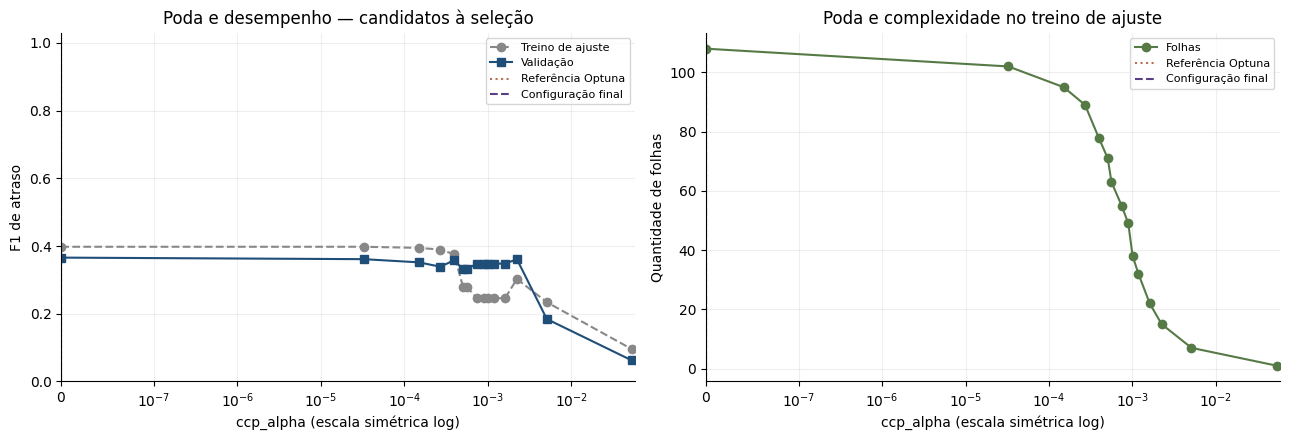

Seleção conjunta concluída. Parâmetros e limiar finais estão congelados antes do reajuste e do teste.


In [15]:
def selecionar_candidatos(candidatos):
    # Mesmos parâmetros + mesma semente representam a mesma configuração.
    # Preserva a primeira ocorrência (Optuna antes da curva), sem duplicar o ranking.
    unicos = {}
    for candidato in candidatos:
        chave = tuple(sorted(candidato["model_params"].items()))
        if chave not in unicos:
            unicos[chave] = {**candidato, **candidato["model_params"]}
    if not unicos:
        raise RuntimeError("Não há configurações concluídas para selecionar.")
    ranking = pd.DataFrame(unicos.values()).sort_values(
        ["val_f1_atraso", "val_pr_auc_atraso", "val_recall_atraso", "val_precision_atraso",
         "leaves", "depth", "ordem_avaliacao"],
        ascending=[False, False, False, False, True, True, True], kind="stable",
    ).reset_index(drop=True)
    ranking["selecionado_final"] = ranking.index == 0
    return ranking


params_sem_poda = {**params_referencia_optuna, "ccp_alpha": 0.0}
caminho = DecisionTreeClassifier(random_state=model_seed, class_weight=None, **params_sem_poda).cost_complexity_pruning_path(X_fit_ajuste, y_fit_ajuste)
alphas_caminho = np.unique(np.maximum(caminho.ccp_alphas, 0.0))
posicoes = np.unique(np.linspace(0, len(alphas_caminho) - 1, min(15, len(alphas_caminho))).round().astype(int))
alphas_diagnostico = np.unique(np.r_[0.0, alphas_caminho[posicoes], params_referencia_optuna["ccp_alpha"]])
linhas_poda = []
candidatos_poda = []
for indice, alpha in enumerate(alphas_diagnostico):
    params_poda = {**params_referencia_optuna, "ccp_alpha": float(alpha)}
    _, dados = avaliar_configuracao(params_poda, X_fit_ajuste, y_fit_ajuste, X_tr, y_tr, X_va, y_va)
    linhas_poda.append({"ccp_alpha": float(alpha),
                        "referencia_optuna": bool(alpha == params_referencia_optuna["ccp_alpha"]), **dados})
    candidatos_poda.append({"candidate_id": f"poda_{indice + 1}", "origem": "Curva de poda",
                            "ordem_avaliacao": len(study.trials) + indice,
                            "model_params": dict(params_poda), **dados})

candidatos_optuna = [
    {"candidate_id": f"optuna_{t.number + 1}", "origem": "Optuna", "ordem_avaliacao": t.number,
     **t.user_attrs} for t in completed_trials
]
ranking_selecao_final = selecionar_candidatos(candidatos_optuna + candidatos_poda)
vencedor_final = ranking_selecao_final.iloc[0]
candidato_final_id = str(vencedor_final["candidate_id"])
origem_modelo_final = str(vencedor_final["origem"])
best_params_v3 = dict(vencedor_final["model_params"])
best_threshold_v3 = float(vencedor_final["best_threshold"])

# Registra a configuração usada de fato nas etapas seguintes, separada da referência.
df_tuning["selecionado_final"] = df_tuning["candidate"].map(lambda c: f"optuna_{c}").eq(candidato_final_id)
diagnostico_poda = pd.DataFrame(linhas_poda).sort_values("ccp_alpha").reset_index(drop=True)
estrutura_final_igual = all(
    best_params_v3[k] == params_referencia_optuna[k]
    for k in params_referencia_optuna if k != "ccp_alpha"
)
diagnostico_poda["selecionado_final"] = (
    diagnostico_poda["ccp_alpha"].eq(best_params_v3["ccp_alpha"]) & estrutura_final_igual
)

print(f"Optuna: {len(completed_trials)} trials concluídos | Curva de poda: {len(candidatos_poda)} candidatos avaliados")
print(f"Ranking final: {len(ranking_selecao_final)} configurações distintas após eliminar repetições.")
print("Critério: F1 → AP → Recall → Precision → menos folhas → menor profundidade → ordem de avaliação")
colunas_ranking = ["candidate_id", "origem", "selecionado_final", "val_f1_atraso", "val_pr_auc_atraso",
                   "val_recall_atraso", "val_precision_atraso", "best_threshold", "depth", "leaves",
                   "ccp_alpha", "max_depth", "min_samples_leaf", "min_samples_split", "max_features", "criterion"]
display(ranking_selecao_final[colunas_ranking].head(15).round(6))
print(f"Vencedor final: {candidato_final_id} | Origem: {origem_modelo_final}")
print(f"F1 validação: {vencedor_final['val_f1_atraso']:.6f} | AP validação: {vencedor_final['val_pr_auc_atraso']:.6f}")
print(f"Folhas na seleção: {int(vencedor_final['leaves'])} | Profundidade na seleção: {int(vencedor_final['depth'])}")
print(f"Limiar congelado: {best_threshold_v3:.8g} | Parâmetros finais: {best_params_v3}")
print("Curva controlada a partir da referência do Optuna:")
display(diagnostico_poda[["ccp_alpha", "referencia_optuna", "selecionado_final", "depth", "leaves", "best_threshold",
                         "train_f1_atraso", "val_f1_atraso", "val_pr_auc_atraso",
                         "gap_f1_treino_validacao"]].round(6))

fig, axs = plt.subplots(1, 2, figsize=(13, 4.5))
axs[0].plot(diagnostico_poda["ccp_alpha"], diagnostico_poda["train_f1_atraso"], "o--", label="Treino de ajuste", color="#888888")
axs[0].plot(diagnostico_poda["ccp_alpha"], diagnostico_poda["val_f1_atraso"], "s-", label="Validação", color=CORES["f1"])
axs[0].set(xlabel="ccp_alpha (escala simétrica log)", ylabel="F1 de atraso", title="Poda e desempenho — candidatos à seleção")
axs[0].set_ylim(0, 1.03)
axs[1].plot(diagnostico_poda["ccp_alpha"], diagnostico_poda["leaves"], "o-", color=CORES["recall"], label="Folhas")
axs[1].set(xlabel="ccp_alpha (escala simétrica log)", ylabel="Quantidade de folhas", title="Poda e complexidade no treino de ajuste")
for ax in axs:
    ax.set_xscale("symlog", linthresh=1e-7)
    ax.set_xlim(0, max(float(diagnostico_poda["ccp_alpha"].max()) * 1.1, 1e-7))
    ax.axvline(params_referencia_optuna["ccp_alpha"], color=CORES["precision"], linestyle=":", label="Referência Optuna")
    if estrutura_final_igual:
        ax.axvline(best_params_v3["ccp_alpha"], color="#5B3E85", linestyle="--", label="Configuração final")
    ax.grid(alpha=0.2)
    ax.legend(fontsize=8)
plt.tight_layout()
plt.show()
print("Seleção conjunta concluída. Parâmetros e limiar finais estão congelados antes do reajuste e do teste.")

## Limiar escolhido: efeito sobre alertas e erros na validação
A árvore retorna probabilidades discretas por folha. A tabela compara o limiar do vencedor da seleção conjunta
com 0,50 e mostra os melhores candidatos. As curvas usam somente a validação do modelo
ajustado no passado; o teste não entra nesta análise. Falsos positivos são alertas de atraso
em pedidos entregues no prazo; falsos negativos são atrasos que passaram sem alerta.

O limiar é congelado antes do reajuste em treino + validação. Esse reajuste pode mudar
as probabilidades e a estrutura das folhas; a mesma qualidade observada na validação
não é garantida para a árvore reajustada. Não se recalcula o limiar com os rótulos do teste.

,cenario,limiar,precision,recall,f1,f2,fp,fn,tp,tn,alertas
23,"Referência 0,50",0.500000,0.083528,0.652439,0.148097,0.276200,1174,57,107,3772,1281
47,Escolhido na validação,0.889908,0.379085,0.353659,0.365931,0.358467,95,106,58,4851,153


Melhores limiares; empates usam proximidade a 0,50 e menor limiar:


,limiar,precision,recall,f1,f2,tn,fp,fn,tp,alertas
47,0.889908,0.379085,0.353659,0.365931,0.358467,4851,95,106,58,153
46,0.883871,0.367089,0.353659,0.360248,0.356265,4846,100,106,58,158
45,0.855330,0.285714,0.378049,0.325459,0.355097,4791,155,102,62,217
44,0.821429,0.283105,0.378049,0.323760,0.354286,4789,157,102,62,219
48,0.910448,0.455556,0.250000,0.322835,0.274799,4897,49,123,41,90
49,0.912088,0.436782,0.231707,0.302789,0.255720,4897,49,126,38,87
43,0.817156,0.215385,0.426829,0.286299,0.356779,4691,255,94,70,325
42,0.800000,0.212121,0.426829,0.283401,0.354970,4686,260,94,70,330
41,0.787879,0.210843,0.426829,0.282258,0.354251,4684,262,94,70,332
51,0.928270,0.484375,0.189024,0.271930,0.215278,4913,33,133,31,64


Probabilidades distintas: 57; limiares avaliados: 58.


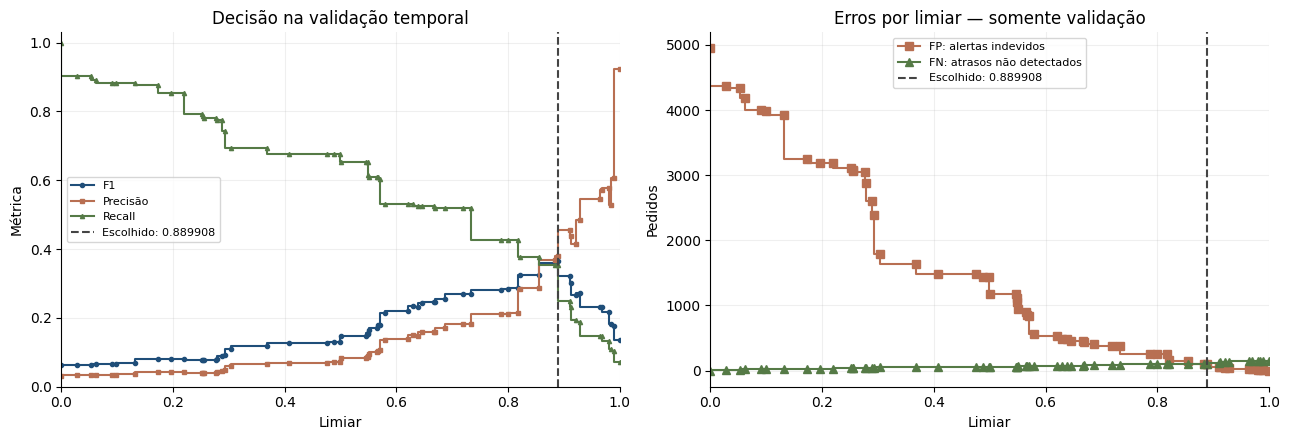

In [16]:
modelo_selecao, dados_selecao = avaliar_configuracao(best_params_v3, X_fit_ajuste, y_fit_ajuste, X_tr, y_tr, X_va, y_va)
proba_validacao = modelo_selecao.predict_proba(X_va)[:, 1]
_, melhor_limiar_validacao, df_limiares_validacao = escolher_limiar(y_va, proba_validacao)
referencia_limiares = df_limiares_validacao.loc[df_limiares_validacao["limiar"].isin([0.5, best_threshold_v3])].copy()
referencia_limiares["cenario"] = np.where(referencia_limiares["limiar"] == best_threshold_v3, "Escolhido na validação", "Referência 0,50")
display(referencia_limiares[["cenario", "limiar", "precision", "recall", "f1", "f2", "fp", "fn", "tp", "tn", "alertas"]].round(6))
print("Melhores limiares; empates usam proximidade a 0,50 e menor limiar:")
display(df_limiares_validacao.assign(distancia_050=lambda t: (t["limiar"] - 0.5).abs()).sort_values(
    ["f1", "recall", "precision", "distancia_050", "limiar"],
    ascending=[False, False, False, True, True], kind="stable",
).drop(columns="distancia_050").head(12).round(6))
print(f"Probabilidades distintas: {np.unique(proba_validacao).size}; limiares avaliados: {len(df_limiares_validacao)}.")

fig, axs = plt.subplots(1, 2, figsize=(13, 4.5))
for metrica, rotulo, marcador in [("f1", "F1", "o"), ("precision", "Precisão", "s"), ("recall", "Recall", "^")]:
    axs[0].step(df_limiares_validacao["limiar"], df_limiares_validacao[metrica], where="pre",
                marker=marcador, markersize=3, color=CORES[metrica], label=rotulo)
axs[0].set(xlabel="Limiar", ylabel="Métrica", title="Decisão na validação temporal", ylim=(0, 1.03))
axs[1].step(df_limiares_validacao["limiar"], df_limiares_validacao["fp"], where="pre", marker="s", label="FP: alertas indevidos", color=CORES["precision"])
axs[1].step(df_limiares_validacao["limiar"], df_limiares_validacao["fn"], where="pre", marker="^", label="FN: atrasos não detectados", color=CORES["recall"])
axs[1].set(xlabel="Limiar", ylabel="Pedidos", title="Erros por limiar — somente validação")
for ax in axs:
    ax.axvline(best_threshold_v3, linestyle="--", color="#444444", label=f"Escolhido: {best_threshold_v3:.6g}")
    ax.set_xlim(0, 1)
    ax.grid(alpha=0.2)
    ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

## 3. Reajuste final e teste
Após a seleção, o amostrador atua sobre o conjunto de treino final. A árvore é reajustada nessa nova amostra e usa o limiar congelado. As métricas de treino usam o conjunto anterior à sobreamostragem. O teste conserva todos os pedidos elegíveis.

,etapa,classe,antes,depois,copias_adicionadas
0,reajuste_final,0,27731,27731,0
1,reajuste_final,1,1367,27731,26364


Metricas no teste (foco em atraso e F1-score):


,Teste
accuracy_atraso,0.8260
precision_atraso,0.3225
recall_atraso,0.6641
f1_atraso,0.4341
f2_atraso,0.5480
roc_auc_atraso,0.7985
pr_auc_atraso,0.3918
balanced_accuracy_atraso,0.7541
mcc_atraso,0.3772
brier_score_atraso,0.3239



Como interpretar as metricas:
- f1_atraso: media harmonica entre precision e recall (metrica principal para comparacao dos modelos).
- precision_atraso: entre os pedidos previstos como atraso, quantos realmente atrasaram.
- recall_atraso: entre os pedidos que realmente atrasaram, quantos o modelo conseguiu detectar.
- f2_atraso: semelhante ao F1, mas dando mais peso ao recall (bom para nao perder atrasos).
- roc_auc_atraso: capacidade de separar atraso vs nao atraso em todos os limiares (quanto maior, melhor).
- pr_auc_atraso: qualidade do modelo no trade-off precision x recall para classe rara (atraso).


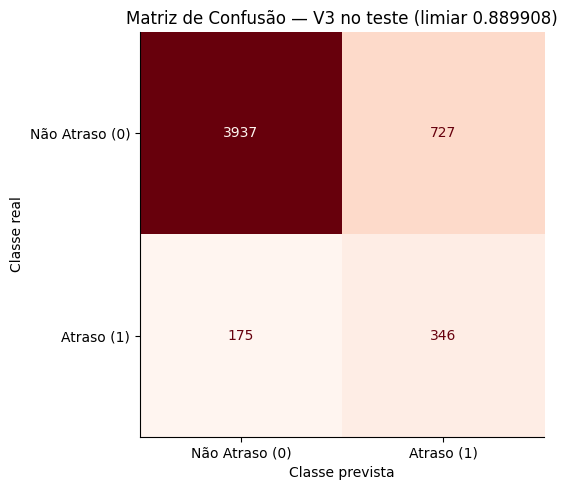

Resumo (teste):
- Limiar adotado: 0.889908
- F1 atraso (Principal): 0.4341
- Precision atraso: 0.3225
- Recall atraso: 0.6641
- F2 atraso: 0.5480
- ROC-AUC atraso: 0.7985
- AP atraso (chave histórica PR-AUC): 0.3918

Classification report (teste):
              precision    recall  f1-score   support

  Não Atraso       0.96      0.84      0.90      4664
      Atraso       0.32      0.66      0.43       521

    accuracy                           0.83      5185
   macro avg       0.64      0.75      0.67      5185
weighted avg       0.89      0.83      0.85      5185



In [17]:
# Celula 5: treino final do modelo com os melhores hiperparametros + avaliacao no teste.
model_v3 = DecisionTreeClassifier(
    random_state=model_seed,
    class_weight=None,
    **best_params_v3,
)

# Mesmo retreino final do XGBoost: treino de ajuste + validacao apos o expurgo.
# O teste fica fora do fit; os parametros e o limiar ja foram fixados.
X_fit_final, y_fit_final, distribuicao_final = balancear_treino(X_train, y_train, "reajuste_final")
distribuicao_balanceamento = pd.concat([distribuicao_ajuste, distribuicao_final], ignore_index=True)
model_v3.fit(X_fit_final, y_fit_final)

# Probabilidade de atraso (classe 1).
y_proba_v3_train = model_v3.predict_proba(X_train)[:, 1]
y_proba_v3_test = model_v3.predict_proba(X_test)[:, 1]

y_pred_v3_train = (y_proba_v3_train >= best_threshold_v3).astype(int)
y_pred_v3_test = (y_proba_v3_test >= best_threshold_v3).astype(int)

res_v3_train = metricas_atraso(y_train, y_pred_v3_train, y_proba_v3_train)
res_v3_test = metricas_atraso(y_test, y_pred_v3_test, y_proba_v3_test)
metricas_treino_v3 = metricas_gerais(y_train, y_pred_v3_train, y_proba_v3_train)
metricas_teste_v3 = metricas_gerais(y_test, y_pred_v3_test, y_proba_v3_test)

print("Metricas no teste (foco em atraso e F1-score):")
display(pd.DataFrame(pd.Series(res_v3_test, name="Teste")).round(4))

# Explicacao breve das metricas para leitura dos resultados.
print("\nComo interpretar as metricas:")
print("- f1_atraso: media harmonica entre precision e recall (metrica principal para comparacao dos modelos).")
print("- precision_atraso: entre os pedidos previstos como atraso, quantos realmente atrasaram.")
print("- recall_atraso: entre os pedidos que realmente atrasaram, quantos o modelo conseguiu detectar.")
print("- f2_atraso: semelhante ao F1, mas dando mais peso ao recall (bom para nao perder atrasos).")
print("- roc_auc_atraso: capacidade de separar atraso vs nao atraso em todos os limiares (quanto maior, melhor).")
print("- pr_auc_atraso: qualidade do modelo no trade-off precision x recall para classe rara (atraso).")

# Exibe matriz de confusao para visualizar erros no teste.
fig, ax = plt.subplots(figsize=(6.5, 5))
ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred_v3_test, cmap="Reds", ax=ax, colorbar=False,
    display_labels=["Não Atraso (0)", "Atraso (1)"]
)
ax.set_xlabel("Classe prevista")
ax.set_ylabel("Classe real")
ax.set_title(f"Matriz de Confusão — V3 no teste (limiar {best_threshold_v3:.6g})")
plt.tight_layout()
plt.show()

print("Resumo (teste):")
print(f"- Limiar adotado: {best_threshold_v3:.6g}")
print(f"- F1 atraso (Principal): {res_v3_test['f1_atraso']:.4f}")
print(f"- Precision atraso: {res_v3_test['precision_atraso']:.4f}")
print(f"- Recall atraso: {res_v3_test['recall_atraso']:.4f}")
print(f"- F2 atraso: {res_v3_test['f2_atraso']:.4f}")
print(f"- ROC-AUC atraso: {res_v3_test['roc_auc_atraso']:.4f}")
print(f"- AP atraso (chave histórica PR-AUC): {res_v3_test['pr_auc_atraso']:.4f}")

print("\nClassification report (teste):")
print(classification_report(y_test, y_pred_v3_test, target_names=["Não Atraso", "Atraso"], zero_division=0))

In [18]:
# Celula 6: tabelas de metricas de atraso (classe 1).
print("=" * 120)
print("METRICAS DE ATRASO (CLASSE 1)")
print("=" * 120)

print("\n(Accuracy, Precision, Recall, F1, F2, ROC-AUC, AP, Balanced Accuracy, MCC, Brier Score, Log Loss)")

print("\n" + "-" * 120)
print("TREINO COMPLETO (ATRASO)")
print("-" * 120)
df_v3_train_atraso = pd.DataFrame(pd.Series(res_v3_train, name="Treino"))
display(df_v3_train_atraso.round(4))

print("\n" + "-" * 120)
print("TESTE (ATRASO)")
print("-" * 120)
df_v3_test_atraso = pd.DataFrame(pd.Series(res_v3_test, name="Teste"))
display(df_v3_test_atraso.round(4))

# ============================================================================
# RESUMO
# ============================================================================
print("RESUMO\n")
print("─" * 120 + "\n")
print(f"  Limiar utilizado: {best_threshold_v3:.6g}")
print(
    f"  Treino - F1 (Atraso): {res_v3_train['f1_atraso']:.4f}, Precision (Atraso): {res_v3_train['precision_atraso']:.4f}, "
    f"Recall (Atraso): {res_v3_train['recall_atraso']:.4f}, AP: {res_v3_train['pr_auc_atraso']:.4f}, ROC-AUC: {metricas_treino_v3['ROC-AUC']:.4f}"
)
print(
    f"  Teste  - F1 (Atraso): {res_v3_test['f1_atraso']:.4f}, Precision (Atraso): {res_v3_test['precision_atraso']:.4f}, "
    f"Recall (Atraso): {res_v3_test['recall_atraso']:.4f}, AP: {res_v3_test['pr_auc_atraso']:.4f}, ROC-AUC: {metricas_teste_v3['ROC-AUC']:.4f}"
)


# Comparacao dos mesmos resultados com diferenca treino-teste.
comparacao_treino_teste = pd.DataFrame({
    "Metrica": ["Acurácia global", "Precision atraso", "Recall atraso", "F1 atraso", "F2 atraso", "ROC-AUC", "AP"],
    "Treino": [
        metricas_treino_v3["Accuracy"], res_v3_train["precision_atraso"], res_v3_train["recall_atraso"],
        res_v3_train["f1_atraso"], res_v3_train["f2_atraso"], res_v3_train["roc_auc_atraso"],
        res_v3_train["pr_auc_atraso"]
    ],
    "Teste": [
        metricas_teste_v3["Accuracy"], res_v3_test["precision_atraso"], res_v3_test["recall_atraso"],
        res_v3_test["f1_atraso"], res_v3_test["f2_atraso"], res_v3_test["roc_auc_atraso"],
        res_v3_test["pr_auc_atraso"]
    ],
})
comparacao_treino_teste["Gap (Treino-Teste)"] = comparacao_treino_teste["Treino"] - comparacao_treino_teste["Teste"]
print("\nCOMPARAÇÃO TREINO X TESTE — diferença descritiva entre períodos e amostras")
display(comparacao_treino_teste.round(4))

print("O gap treino–teste é descritivo: prevalência e mudança temporal também influenciam as métricas.")

METRICAS DE ATRASO (CLASSE 1)

(Accuracy, Precision, Recall, F1, F2, ROC-AUC, AP, Balanced Accuracy, MCC, Brier Score, Log Loss)

------------------------------------------------------------------------------------------------------------------------
TREINO COMPLETO (ATRASO)
------------------------------------------------------------------------------------------------------------------------


,Treino
accuracy_atraso,0.9550
precision_atraso,0.5345
recall_atraso,0.3233
f1_atraso,0.4029
f2_atraso,0.3511
roc_auc_atraso,0.8699
pr_auc_atraso,0.4262
balanced_accuracy_atraso,0.6547
mcc_atraso,0.3940
brier_score_atraso,0.1386



------------------------------------------------------------------------------------------------------------------------
TESTE (ATRASO)
------------------------------------------------------------------------------------------------------------------------


,Teste
accuracy_atraso,0.8260
precision_atraso,0.3225
recall_atraso,0.6641
f1_atraso,0.4341
f2_atraso,0.5480
roc_auc_atraso,0.7985
pr_auc_atraso,0.3918
balanced_accuracy_atraso,0.7541
mcc_atraso,0.3772
brier_score_atraso,0.3239


RESUMO

────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────

  Limiar utilizado: 0.889908
  Treino - F1 (Atraso): 0.4029, Precision (Atraso): 0.5345, Recall (Atraso): 0.3233, AP: 0.4262, ROC-AUC: 0.8699
  Teste  - F1 (Atraso): 0.4341, Precision (Atraso): 0.3225, Recall (Atraso): 0.6641, AP: 0.3918, ROC-AUC: 0.7985

COMPARAÇÃO TREINO X TESTE — diferença descritiva entre períodos e amostras


,Metrica,Treino,Teste,Gap (Treino-Teste)
0,Acurácia global,0.9550,0.8260,0.1289
1,Precision atraso,0.5345,0.3225,0.2120
2,Recall atraso,0.3233,0.6641,-0.3408
3,F1 atraso,0.4029,0.4341,-0.0312
4,F2 atraso,0.3511,0.5480,-0.1969
5,ROC-AUC,0.8699,0.7985,0.0714
6,AP,0.4262,0.3918,0.0345


O gap treino–teste é descritivo: prevalência e mudança temporal também influenciam as métricas.


## 4. Regras da árvore e decisão por limiar
Cada folha informa a proporção de atrasos na amostra balanceada de reajuste. Essa proporção é o escore utilizado para gerar o alerta. A tabela mostra a classe majoritária, a decisão pelo limiar, o suporte no treino efetivamente usado e a taxa de atraso observada no teste. Os caminhos completos são exportados em regras_folhas.csv.

Na tabela, suporte_treino conta as linhas usadas no reajuste, inclusive cópias. suporte_treino_original conta as linhas do treino final antes da sobreamostragem. O suporte de teste conta os pedidos na distribuição original.

Profundidade: 8 | Folhas: 132 | Nós: 263
Decisão operacional: p_atraso >= 0.88990826
A tabela completa será exportada; amostra por suporte no treino:


,folha,regra,suporte_treino,p_atraso,classe_majoritaria,decisao_limiar,suporte_treino_pct,suporte_treino_original,suporte_teste,atrasos_teste,fp_teste,fn_teste,taxa_atraso_teste
0,239,(carrier_available_days > 8.5 OU ausente) E (delivery_time_per_km > 0.05959849990904331 OU ausen...,3906,0.103687,No prazo,No prazo,7.042660,3522,190,0,0,0,0.000000
1,198,(carrier_available_days > 8.5 OU ausente) E (delivery_time_per_km > 0.05959849990904331 OU ausen...,3462,0.207683,No prazo,No prazo,6.242112,2779,119,0,0,0,0.000000
2,187,(carrier_available_days > 8.5 OU ausente) E (delivery_time_per_km > 0.05959849990904331 OU ausen...,2586,0.360789,No prazo,No prazo,4.662652,1700,115,0,0,0,0.000000
3,15,(carrier_available_days <= 8.5 E presente) E (carrier_available_days <= 5.5 E presente) E (produ...,2275,0.997802,Atraso,Atraso,4.101908,111,299,184,115,0,0.615385
4,112,(carrier_available_days > 8.5 OU ausente) E (delivery_time_per_km <= 0.05959849990904331 E prese...,2203,0.899682,Atraso,Atraso,3.972089,316,0,0,0,0,NaN
5,224,(carrier_available_days > 8.5 OU ausente) E (delivery_time_per_km > 0.05959849990904331 OU ausen...,1802,0.426748,No prazo,No prazo,3.249071,1074,160,3,0,3,0.018750
6,208,(carrier_available_days > 8.5 OU ausente) E (delivery_time_per_km > 0.05959849990904331 OU ausen...,1633,0.845070,Atraso,No prazo,2.944358,318,0,0,0,0,NaN
7,163,(carrier_available_days > 8.5 OU ausente) E (delivery_time_per_km <= 0.05959849990904331 E prese...,1625,0.271385,No prazo,No prazo,2.929934,1207,87,0,0,0,0.000000
8,221,(carrier_available_days > 8.5 OU ausente) E (delivery_time_per_km > 0.05959849990904331 OU ausen...,1484,0.725741,Atraso,No prazo,2.675706,461,192,3,0,3,0.015625
9,188,(carrier_available_days > 8.5 OU ausente) E (delivery_time_per_km > 0.05959849990904331 OU ausen...,1476,0.168699,No prazo,No prazo,2.661282,1239,178,2,0,2,0.011236


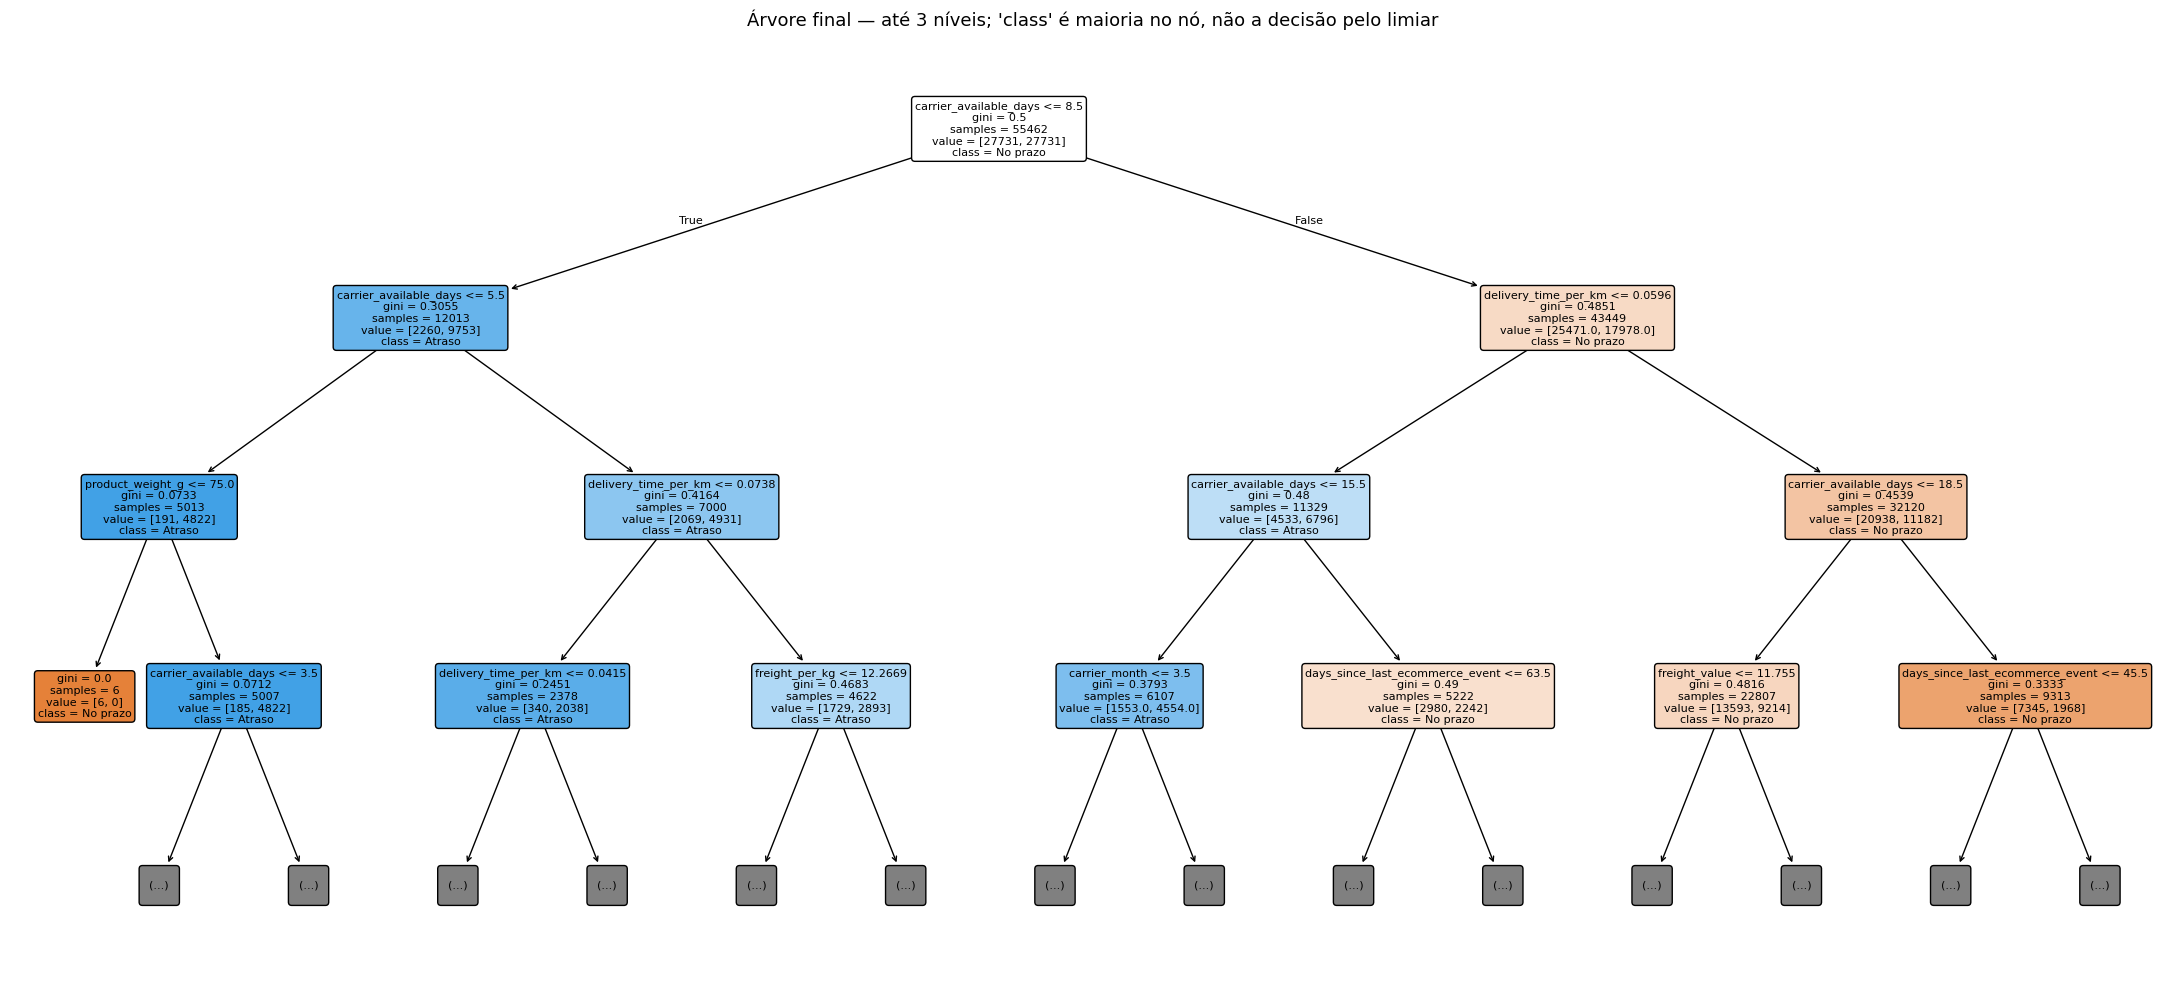

In [19]:
def extrair_regras_folhas(modelo, feature_names, limiar):
    arvore = modelo.tree_
    classe_positiva = list(modelo.classes_).index(1)
    linhas = []
    pilha = [(0, [])]
    while pilha:
        no, condicoes = pilha.pop()
        esquerda, direita = arvore.children_left[no], arvore.children_right[no]
        if esquerda == direita:
            valores = np.asarray(arvore.value[no][0], dtype=float)
            p_atraso = float(valores[classe_positiva] / valores.sum())
            linhas.append({
                "folha": no,
                "regra": " E ".join(condicoes) if condicoes else "Todos os pedidos (sem divisões)",
                "suporte_treino": int(arvore.n_node_samples[no]),
                "p_atraso": p_atraso,
                "classe_majoritaria": "Atraso" if modelo.classes_[np.argmax(valores)] == 1 else "No prazo",
                "decisao_limiar": "Atraso" if p_atraso >= limiar else "No prazo",
            })
            continue
        feature = feature_names[arvore.feature[no]]
        corte = repr(float(arvore.threshold[no]))
        # Quando a versão do sklearn registra o caminho de ausentes, inclui essa condição.
        missing_left = bool(arvore.missing_go_to_left[no]) if hasattr(arvore, "missing_go_to_left") else None
        cond_esquerda = f"{feature} <= {corte}"
        cond_direita = f"{feature} > {corte}"
        if missing_left is not None:
            cond_esquerda = f"({cond_esquerda} OU ausente)" if missing_left else f"({cond_esquerda} E presente)"
            cond_direita = f"({cond_direita} E presente)" if missing_left else f"({cond_direita} OU ausente)"
        pilha.append((direita, condicoes + [cond_direita]))
        pilha.append((esquerda, condicoes + [cond_esquerda]))
    return pd.DataFrame(linhas).sort_values("suporte_treino", ascending=False).reset_index(drop=True)


regras_folhas = extrair_regras_folhas(model_v3, list(X_train.columns), best_threshold_v3)
regras_folhas["suporte_treino_pct"] = 100 * regras_folhas["suporte_treino"] / len(X_fit_final)
contagem_original = pd.Series(model_v3.apply(X_train)).value_counts()
regras_folhas["suporte_treino_original"] = regras_folhas["folha"].map(contagem_original).fillna(0).astype(int)
folhas_teste = model_v3.apply(X_test)
por_folha_teste = pd.DataFrame({"folha": folhas_teste, "real": np.asarray(y_test), "predito": y_pred_v3_test})
por_folha_teste["fp"] = ((por_folha_teste["real"] == 0) & (por_folha_teste["predito"] == 1)).astype(int)
por_folha_teste["fn"] = ((por_folha_teste["real"] == 1) & (por_folha_teste["predito"] == 0)).astype(int)
resumo_folhas_teste = por_folha_teste.groupby("folha").agg(
    suporte_teste=("real", "size"), atrasos_teste=("real", "sum"), fp_teste=("fp", "sum"), fn_teste=("fn", "sum"),
).reset_index()
regras_folhas = regras_folhas.merge(resumo_folhas_teste, on="folha", how="left")
for coluna in ["suporte_teste", "atrasos_teste", "fp_teste", "fn_teste"]:
    regras_folhas[coluna] = regras_folhas[coluna].fillna(0).astype(int)
regras_folhas["taxa_atraso_teste"] = regras_folhas["atrasos_teste"].div(regras_folhas["suporte_teste"].replace(0, np.nan))
print(f"Profundidade: {model_v3.get_depth()} | Folhas: {model_v3.get_n_leaves()} | Nós: {model_v3.tree_.node_count}")
print(f"Decisão operacional: p_atraso >= {best_threshold_v3:.8g}")
print("A tabela completa será exportada; amostra por suporte no treino:")
with pd.option_context("display.max_colwidth", 100):
    display(regras_folhas.head(20).round(6))

fig, ax = plt.subplots(figsize=(22, 10))
plot_tree(model_v3, feature_names=list(X_train.columns), class_names=["No prazo", "Atraso"],
          filled=True, rounded=True, fontsize=8, max_depth=3, precision=4, ax=ax)
ax.set_title("Árvore final — até 3 níveis; 'class' é maioria no nó, não a decisão pelo limiar", fontsize=13)
plt.tight_layout()
plt.show()

=== Importância das features — Árvore de Decisão ===


,feature,importance,importance_pct
0,carrier_available_days,0.4269,42.6887
1,delivery_time_per_km,0.1341,13.4106
2,days_since_last_ecommerce_event,0.0842,8.4246
3,freight_value,0.0822,8.2228
4,carrier_month,0.0465,4.6453
5,price,0.0366,3.6600
6,days_until_next_ecommerce_event,0.0341,3.4056
7,product_density,0.0331,3.3149
8,freight_per_kg,0.0224,2.2392
9,volume_cm3,0.0207,2.0663


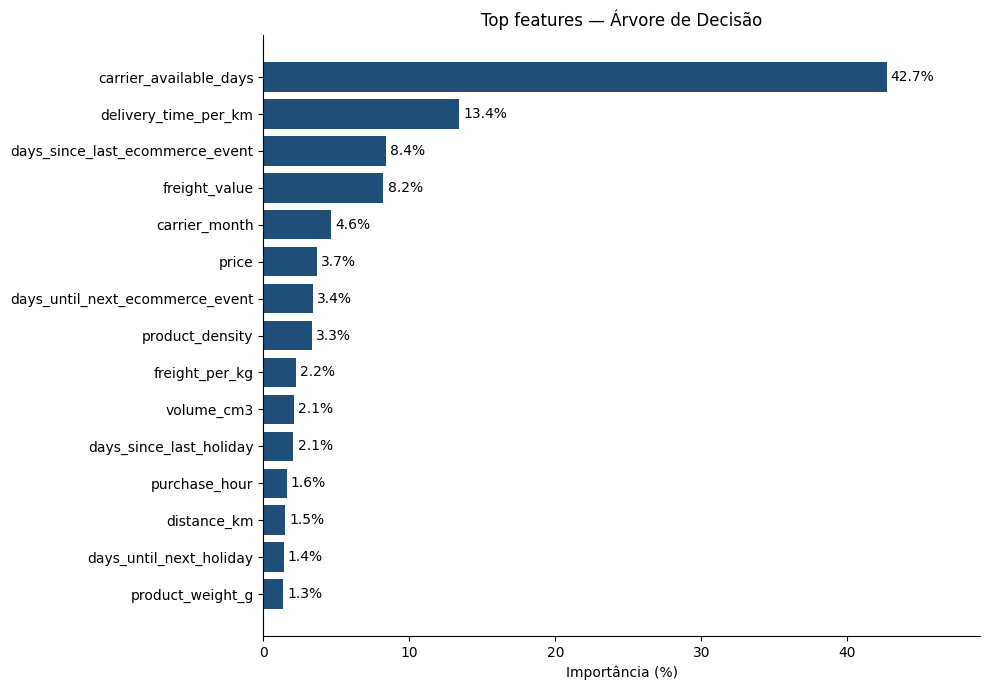


INSIGHTS:
- As primeiras posições mostram quais variáveis mais contribuíram para as divisões da árvore.
- Importância igual a zero indica que a feature não foi utilizada em nenhuma divisão do modelo final.
- Em árvores, a importância deve ser interpretada junto com as regras e com as métricas de generalização;
  uma feature muito dominante não significa, sozinha, relação causal com o atraso.


In [20]:
# Celula 8: INSIGHT ESPECIFICO DA ARVORE — importancia das features.
importance_df = pd.DataFrame({
    "feature": X_train.columns,
    "importance": model_v3.feature_importances_,
}).sort_values("importance", ascending=False).reset_index(drop=True)

importance_df["importance_pct"] = importance_df["importance"] * 100

print("=== Importância das features — Árvore de Decisão ===")
display(importance_df.round(4))

top_n = min(15, len(importance_df))
plot_df = importance_df.loc[importance_df["importance"] > 0].head(top_n).sort_values("importance_pct")
plt.figure(figsize=(10, 7))
barras = plt.barh(plot_df["feature"], plot_df["importance_pct"], color=CORES["f1"])
plt.bar_label(barras, fmt="%.1f%%", padding=3)
if plot_df.empty:
    plt.text(0.5, 0.5, "Árvore sem divisões: importâncias iguais a zero", transform=plt.gca().transAxes, ha="center")
else:
    plt.xlim(0, plot_df["importance_pct"].max() * 1.15)
plt.xlabel("Importância (%)")
plt.title("Top features — Árvore de Decisão")
plt.tight_layout()
plt.show()

print("\nINSIGHTS:")
print("- As primeiras posições mostram quais variáveis mais contribuíram para as divisões da árvore.")
print("- Importância igual a zero indica que a feature não foi utilizada em nenhuma divisão do modelo final.")
print("- Em árvores, a importância deve ser interpretada junto com as regras e com as métricas de generalização;")
print("  uma feature muito dominante não significa, sozinha, relação causal com o atraso.")

## 5. Onde a árvore erra no teste
Tipo	Significado	Consequência operacional
VP	Atraso com alerta	Atraso identificado
VN	Entrega no prazo sem alerta	Pedido liberado corretamente
FP	Entrega no prazo com alerta	Alerta indevido
FN	Atraso sem alerta	Atraso não detectado

As taxas FP/(FP+VN) e FN/(FN+VP) usam como denominador os pedidos da classe real;
não são a proporção de FP ou FN no total. Nos exemplos, FP aparecem por maior probabilidade
prevista e FN por menor probabilidade, permitindo inspecionar os erros mais distantes da
decisão correta. A proximidade ao limiar e a folha ajudam a interpretar cada caso.

linha_df é o índice da tabela após a ordenação cronológica e as remoções já existentes;
não é o número da linha do CSV original. Se houver um ID de pedido na base, ele também
é preservado no relatório. A análise descreve associações e não explica causas de atraso.

,tipo,significado,pedidos,percentual_teste
0,VN,No prazo sem alerta,3937,75.93
1,FP,No prazo com alerta,727,14.02
2,FN,Atraso sem alerta,175,3.38
3,VP,Atraso com alerta,346,6.67


Taxa de falsos positivos: 15.59% dos pedidos no prazo.
Taxa de falsos negativos: 33.59% dos pedidos atrasados.

FP: 727 pedidos; até 10 exemplos ordenados por probabilidade.


C:\Users\mateu\AppData\Local\Temp\ipykernel_1660\3626736629.py:39: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  display(exemplos[colunas_exemplo].head(10).round(6))


,linha_df,data_coleta,tipo,p_atraso,distancia_limiar,folha,feature__carrier_available_days,feature__delivery_time_per_km,feature__days_since_last_ecommerce_event,feature__freight_value,regra
1137,30235,2018-07-19 15:00:00+00:00,FP,1.000000,0.110092,72,8,5.270092,37,1.09,(carrier_available_days <= 8.5 E presente) E (carrier_available_days > 5.5 OU ausente)...
1152,30250,2018-07-19 19:26:00+00:00,FP,1.000000,0.110092,53,7,0.066548,37,8.88,(carrier_available_days <= 8.5 E presente) E (carrier_available_days > 5.5 OU ausente)...
2294,31392,2018-08-01 13:36:00+00:00,FP,1.000000,0.110092,53,6,0.066028,50,7.39,(carrier_available_days <= 8.5 E presente) E (carrier_available_days > 5.5 OU ausente)...
2324,31422,2018-08-01 15:17:00+00:00,FP,1.000000,0.110092,53,7,0.060833,50,23.75,(carrier_available_days <= 8.5 E presente) E (carrier_available_days > 5.5 OU ausente)...
3356,32454,2018-08-10 19:07:00+00:00,FP,1.000000,0.110092,53,6,0.061188,59,8.33,(carrier_available_days <= 8.5 E presente) E (carrier_available_days > 5.5 OU ausente)...
4408,33506,2018-08-21 14:46:00+00:00,FP,1.000000,0.110092,53,6,0.044200,9,7.41,(carrier_available_days <= 8.5 E presente) E (carrier_available_days > 5.5 OU ausente)...
1490,30588,2018-07-24 14:14:00+00:00,FP,0.997802,0.107894,15,2,0.019495,42,8.03,(carrier_available_days <= 8.5 E presente) E (carrier_available_days <= 5.5 E presente...
1572,30670,2018-07-24 16:07:00+00:00,FP,0.997802,0.107894,15,2,0.017966,42,8.66,(carrier_available_days <= 8.5 E presente) E (carrier_available_days <= 5.5 E presente...
1931,31029,2018-07-30 10:34:00+00:00,FP,0.997802,0.107894,15,2,0.169276,48,11.47,(carrier_available_days <= 8.5 E presente) E (carrier_available_days <= 5.5 E presente...
1967,31065,2018-07-30 12:51:00+00:00,FP,0.997802,0.107894,15,2,0.048308,48,14.05,(carrier_available_days <= 8.5 E presente) E (carrier_available_days <= 5.5 E presente...



FN: 175 pedidos; até 10 exemplos ordenados por probabilidade.


C:\Users\mateu\AppData\Local\Temp\ipykernel_1660\3626736629.py:39: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  display(exemplos[colunas_exemplo].head(10).round(6))


,linha_df,data_coleta,tipo,p_atraso,distancia_limiar,folha,feature__carrier_available_days,feature__delivery_time_per_km,feature__days_since_last_ecommerce_event,feature__freight_value,regra
927,30025,2018-07-16 13:14:00+00:00,FN,0.0,0.889908,97,8,0.182632,34,7.67,(carrier_available_days <= 8.5 E presente) E (carrier_available_days > 5.5 OU ausente)...
1043,30141,2018-07-18 16:57:00+00:00,FN,0.0,0.889908,97,6,0.120074,36,8.65,(carrier_available_days <= 8.5 E presente) E (carrier_available_days > 5.5 OU ausente)...
1627,30725,2018-07-25 13:32:00+00:00,FN,0.0,0.889908,70,6,0.099613,43,8.90,(carrier_available_days <= 8.5 E presente) E (carrier_available_days > 5.5 OU ausente)...
1892,30990,2018-07-27 14:47:00+00:00,FN,0.0,0.889908,91,6,0.094057,45,7.47,(carrier_available_days <= 8.5 E presente) E (carrier_available_days > 5.5 OU ausente)...
1893,30991,2018-07-27 14:47:00+00:00,FN,0.0,0.889908,91,6,0.094057,45,7.47,(carrier_available_days <= 8.5 E presente) E (carrier_available_days > 5.5 OU ausente)...
2105,31203,2018-07-31 11:24:00+00:00,FN,0.0,0.889908,18,3,0.025003,49,13.90,(carrier_available_days <= 8.5 E presente) E (carrier_available_days <= 5.5 E presente...
2130,31228,2018-07-31 13:12:00+00:00,FN,0.0,0.889908,91,7,0.095031,49,7.46,(carrier_available_days <= 8.5 E presente) E (carrier_available_days > 5.5 OU ausente)...
2416,31514,2018-08-02 14:31:00+00:00,FN,0.0,0.889908,3,1,0.017148,51,7.46,(carrier_available_days <= 8.5 E presente) E (carrier_available_days <= 5.5 E presente...
2447,31545,2018-08-02 18:45:00+00:00,FN,0.0,0.889908,100,7,0.235921,51,8.88,(carrier_available_days <= 8.5 E presente) E (carrier_available_days > 5.5 OU ausente)...
2616,31714,2018-08-06 09:17:00+00:00,FN,0.0,0.889908,3,3,0.044411,55,7.46,(carrier_available_days <= 8.5 E presente) E (carrier_available_days <= 5.5 E presente...



Faixas fixas de probabilidade no teste — apenas descrição:


,pedidos,p_medio,atrasos,taxa_atraso_observada
faixa_probabilidade,,,,
"(-0.001, 0.05]",968,0.0115,41,0.0424
"(0.05, 0.1]",0,NaN,0,NaN
"(0.1, 0.2]",652,0.1291,9,0.0138
"(0.2, 0.5]",800,0.3222,9,0.0112
"(0.5, 1.0]",2765,0.8156,462,0.1671


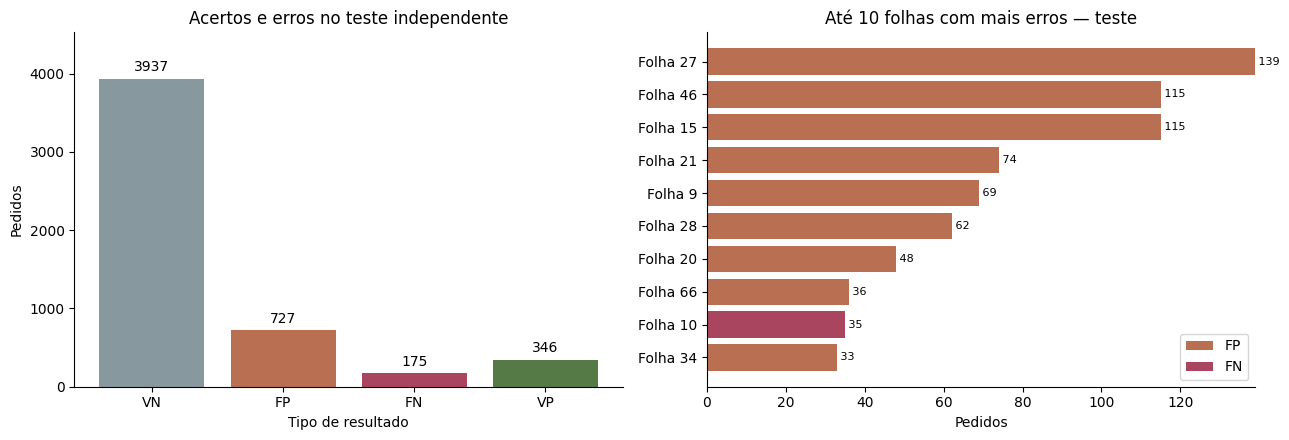

In [21]:
tn, fp, fn, tp = confusion_matrix(y_test, y_pred_v3_test, labels=[0, 1]).ravel()
resumo_erros = pd.DataFrame({
    "tipo": ["VN", "FP", "FN", "VP"],
    "significado": ["No prazo sem alerta", "No prazo com alerta", "Atraso sem alerta", "Atraso com alerta"],
    "pedidos": [tn, fp, fn, tp],
})
resumo_erros["percentual_teste"] = 100 * resumo_erros["pedidos"] / len(y_test)
display(resumo_erros.round(2))
print(f"Taxa de falsos positivos: {fp / (fp + tn):.2%} dos pedidos no prazo.")
print(f"Taxa de falsos negativos: {fn / (fn + tp):.2%} dos pedidos atrasados.")

casos_teste = pd.DataFrame({
    "linha_df": X_test.index.to_numpy(), "data_coleta": carrier_test_dates.to_numpy(),
    "atraso_real": np.asarray(y_test), "atraso_previsto": y_pred_v3_test,
    "p_atraso": y_proba_v3_test, "folha": folhas_teste,
})
casos_teste["tipo"] = np.select([
    (casos_teste["atraso_real"] == 0) & (casos_teste["atraso_previsto"] == 1),
    (casos_teste["atraso_real"] == 1) & (casos_teste["atraso_previsto"] == 0),
    (casos_teste["atraso_real"] == 1) & (casos_teste["atraso_previsto"] == 1),
], ["FP", "FN", "VP"], default="VN")
casos_teste["distancia_limiar"] = (casos_teste["p_atraso"] - best_threshold_v3).abs()
for identificador in ["order_id", "pedido_id", "id_pedido"]:
    if identificador in df.columns:
        casos_teste[identificador] = df.loc[X_test.index, identificador].to_numpy()
# Features realmente disponíveis ao modelo, sem inserir variáveis pós-entrega.
casos_teste = pd.concat([casos_teste.reset_index(drop=True), X_test.reset_index(drop=True).add_prefix("feature__")], axis=1)
casos_teste = casos_teste.merge(regras_folhas[["folha", "regra", "decisao_limiar"]], on="folha", how="left")

features_exemplo = ["feature__" + f for f in importance_df.loc[importance_df["importance"] > 0, "feature"].head(4)]
colunas_exemplo = ["linha_df", "data_coleta", "tipo", "p_atraso", "distancia_limiar", "folha", *features_exemplo, "regra"]
for tipo, crescente in [("FP", False), ("FN", True)]:
    exemplos = casos_teste.loc[casos_teste["tipo"] == tipo].sort_values(["p_atraso", "linha_df"], ascending=[crescente, True])
    print(f"\n{tipo}: {len(exemplos)} pedidos; até 10 exemplos ordenados por probabilidade.")
    if exemplos.empty:
        print("Nenhum caso desse tipo nesta avaliação.")
    else:
        with pd.option_context("display.max_colwidth", 90):
            display(exemplos[colunas_exemplo].head(10).round(6))

# Faixas fixas apenas para descrição, sem escolher um novo limiar no teste.
casos_teste["faixa_probabilidade"] = pd.cut(casos_teste["p_atraso"], bins=[0, .05, .10, .20, .50, 1], include_lowest=True)
perfil_probabilidade = casos_teste.groupby("faixa_probabilidade", observed=False).agg(
    pedidos=("atraso_real", "size"), p_medio=("p_atraso", "mean"),
    atrasos=("atraso_real", "sum"), taxa_atraso_observada=("atraso_real", "mean"),
)
print("\nFaixas fixas de probabilidade no teste — apenas descrição:")
display(perfil_probabilidade.round(4))

fig, axs = plt.subplots(1, 2, figsize=(13, 4.5))
barras = axs[0].bar(resumo_erros["tipo"], resumo_erros["pedidos"], color=["#87999E", "#B86F52", "#AA4560", "#557A46"])
axs[0].bar_label(barras, padding=3)
axs[0].set(title="Acertos e erros no teste independente", xlabel="Tipo de resultado", ylabel="Pedidos")
axs[0].margins(y=0.15)
perfil_erros_folhas = regras_folhas.assign(erros=lambda t: t["fp_teste"] + t["fn_teste"]).query("erros > 0").nlargest(10, "erros").sort_values("erros")
if perfil_erros_folhas.empty:
    axs[1].text(.5, .5, "Nenhum erro no teste", transform=axs[1].transAxes, ha="center")
else:
    rotulos = "Folha " + perfil_erros_folhas["folha"].astype(str)
    axs[1].barh(rotulos, perfil_erros_folhas["fp_teste"], label="FP", color="#B86F52")
    axs[1].barh(rotulos, perfil_erros_folhas["fn_teste"], left=perfil_erros_folhas["fp_teste"], label="FN", color="#AA4560")
    for pos, total in enumerate(perfil_erros_folhas["erros"]):
        axs[1].text(total, pos, f" {int(total)}", va="center", fontsize=8)
    axs[1].margins(x=0.15)
    axs[1].legend()
axs[1].set(title="Até 10 folhas com mais erros — teste", xlabel="Pedidos")
plt.tight_layout()
plt.show()

## Referência de decisão 0,50 versus limiar congelado
Comparação descritiva no teste. Mesmo que 0,50 produza uma métrica melhor no teste,
esta tabela não redefine a escolha feita na validação.

In [22]:
# Celula 9: comparacao no teste do limiar ja escolhido na validacao contra 0.50.
pred_default = (y_proba_v3_test >= 0.50).astype(int)
pred_tuned = y_pred_v3_test

def resumo_threshold(y_true, pred, proba, nome):
    return {
        "Cenario": nome,
        "Accuracy": accuracy_score(y_true, pred),
        "Precision atraso": precision_score(y_true, pred, zero_division=0),
        "Recall atraso": recall_score(y_true, pred, zero_division=0),
        "F1 atraso": f1_score(y_true, pred, zero_division=0),
        "F2 atraso": fbeta_score(y_true, pred, beta=2, zero_division=0),
        "AP": average_precision_score(y_true, proba),
    }

comparacao_threshold = pd.DataFrame([
    resumo_threshold(y_test, pred_default, y_proba_v3_test, "Threshold 0.50"),
    resumo_threshold(y_test, pred_tuned, y_proba_v3_test, f"Threshold otimizado {best_threshold_v3:.6g}"),
])
display(comparacao_threshold.round(4))

print("\nINSIGHT:")
print("- O threshold não altera a árvore treinada nem as probabilidades; ele altera a decisão final de classe.")
print("- Compare o F1 principal, a Precision e o Recall; o teste não escolhe o limiar nem os parâmetros.")

print("A coluna AP usa Average Precision (AP) e independe do limiar aplicado.")

,Cenario,Accuracy,Precision atraso,Recall atraso,F1 atraso,F2 atraso,AP
0,Threshold 0.50,0.5445,0.1671,0.8868,0.2812,0.4764,0.3918
1,Threshold otimizado 0.889908,0.8260,0.3225,0.6641,0.4341,0.5480,0.3918



INSIGHT:
- O threshold não altera a árvore treinada nem as probabilidades; ele altera a decisão final de classe.
- Compare o F1 principal, a Precision e o Recall; o teste não escolhe o limiar nem os parâmetros.
A coluna AP usa Average Precision (AP) e independe do limiar aplicado.


In [23]:
# Celula 10: resumo final com os principais insights da Arvore de Decisao.
print("=" * 100)
print("RESUMO FINAL — ÁRVORE DE DECISÃO V3 COM SOBREAMOSTRAGEM")
print("=" * 100)
print(f"Configuração selecionada: {candidato_final_id} | Origem: {origem_modelo_final}")
print(f"Threshold escolhido na validação temporal: {best_threshold_v3:.8g}")
print(f"Na seleção: {int(vencedor_final['leaves'])} folhas, profundidade {int(vencedor_final['depth'])}; abaixo, estrutura após reajuste.")
print(f"Profundidade: {model_v3.get_depth()} | Folhas: {model_v3.get_n_leaves()} | Nós: {model_v3.tree_.node_count}")
print("\nMelhores hiperparâmetros:")
for k, v in best_params_v3.items():
    print(f" - {k}: {v}")

print("\nMétricas de atraso no TESTE:")
for k in ["precision_atraso", "recall_atraso", "f1_atraso", "f2_atraso", "roc_auc_atraso", "pr_auc_atraso"]:
    print(f" - {k}: {res_v3_test[k]:.4f}")

print("\nTop 10 features:")
display(importance_df.head(10).round(4))

print("\nLEITURA PARA O TCC:")
print("1. Generalização: diferenças treino–teste também refletem prevalência e mudança temporal; não provam sobreajuste sozinhas.")
print("2. Comparação: F1 de atraso é a métrica principal, como no XGBoost; complemente com AP, Recall e F2.")
print("3. Interpretabilidade: profundidade, folhas e regras tornam a árvore mais explicável que modelos de ensemble.")
print("4. Features: discuta as variáveis mais importantes como sinais preditivos, sem tratá-las automaticamente como causas.")
print("5. Threshold: o limiar otimizado mostra o trade-off entre detectar mais atrasos e gerar falsos positivos.")

print("6. Validação fixa: usada no Optuna e no limiar; o teste final não participa dessas escolhas.")

print("7. Regularização: o ranking final reúne Optuna e curva de poda; o reajuste e o pickle usam o vencedor conjunto.")
print("8. Regras: use decisao_limiar na tabela de folhas; class no desenho indica a maioria no nó.")
print(f"9. Erros no teste: FP={fp}, FN={fn}, VP={tp}, VN={tn}. Consulte os exemplos por pedido e por folha.")

RESUMO FINAL — ÁRVORE DE DECISÃO V3 COM SOBREAMOSTRAGEM
Configuração selecionada: optuna_25 | Origem: Optuna
Threshold escolhido na validação temporal: 0.88990826
Na seleção: 108 folhas, profundidade 8; abaixo, estrutura após reajuste.
Profundidade: 8 | Folhas: 132 | Nós: 263

Melhores hiperparâmetros:
 - criterion: gini
 - max_depth: 8
 - min_samples_split: 193
 - min_samples_leaf: 5
 - max_features: None
 - ccp_alpha: 0.0

Métricas de atraso no TESTE:
 - precision_atraso: 0.3225
 - recall_atraso: 0.6641
 - f1_atraso: 0.4341
 - f2_atraso: 0.5480
 - roc_auc_atraso: 0.7985
 - pr_auc_atraso: 0.3918

Top 10 features:


,feature,importance,importance_pct
0,carrier_available_days,0.4269,42.6887
1,delivery_time_per_km,0.1341,13.4106
2,days_since_last_ecommerce_event,0.0842,8.4246
3,freight_value,0.0822,8.2228
4,carrier_month,0.0465,4.6453
5,price,0.0366,3.6600
6,days_until_next_ecommerce_event,0.0341,3.4056
7,product_density,0.0331,3.3149
8,freight_per_kg,0.0224,2.2392
9,volume_cm3,0.0207,2.0663



LEITURA PARA O TCC:
1. Generalização: diferenças treino–teste também refletem prevalência e mudança temporal; não provam sobreajuste sozinhas.
2. Comparação: F1 de atraso é a métrica principal, como no XGBoost; complemente com AP, Recall e F2.
3. Interpretabilidade: profundidade, folhas e regras tornam a árvore mais explicável que modelos de ensemble.
4. Features: discuta as variáveis mais importantes como sinais preditivos, sem tratá-las automaticamente como causas.
5. Threshold: o limiar otimizado mostra o trade-off entre detectar mais atrasos e gerar falsos positivos.
6. Validação fixa: usada no Optuna e no limiar; o teste final não participa dessas escolhas.
7. Regularização: o ranking final reúne Optuna e curva de poda; o reajuste e o pickle usam o vencedor conjunto.
8. Regras: use decisao_limiar na tabela de folhas; class no desenho indica a maioria no nó.
9. Erros no teste: FP=727, FN=175, VP=346, VN=3937. Consulte os exemplos por pedido e por folha.


## 6. Exportação dos resultados da V3
O pickle conserva o nome e as chaves de inferência da V3 original. A pasta resultados_arvore_v3/ reúne os rankings, os limiares, a contagem por classe antes e depois do sorteio, as regras por folha e os erros por pedido. O resumo JSON identifica a configuração vencedora, a versão dos pacotes e o formato de entrada.

In [ ]:
# Exportacao para deploy: MESMO CONTRATO do pickle do XGBoost.
# Executar somente depois de escolher parametros/limiar na validacao e avaliar no teste independente.
import pickle

raw_columns = [
    "purchase_date", "purchase_time", "carrier_datetime", "estimated_delivery_datetime",
    "price", "freight_value", "product_weight_g", "height_cm", "width_cm", "length_cm",
    "distance_km", "same_city", "customer_city", "seller_city", "category_name",
]

artefato_modelo = {
    "modelo": model_v3,
    "balanceamento": "oversampling",
    "hiperparametros": best_params_v3,
    "limiar": float(best_threshold_v3),
    "feature_names": list(X_train.columns),
    "num_cols": num_cols,
    "cat_cols": cat_cols,
    "scaler": scaler,
    "schema_version": 4,
    "inference_moment": "carrier_collection",
    "raw_columns": raw_columns,
    "ecommerce_events": [
        "mothers_day", "fathers_day", "children_day",
        "black_friday", "cyber_monday", "christmas",
    ],
}

nome_arquivo = "arvore_decisao_lastmile_oversampling_model.pkl"
with open(nome_arquivo, "wb") as arquivo:
    pickle.dump(artefato_modelo, arquivo, protocol=pickle.HIGHEST_PROTOCOL)

print(f"Artefato salvo: {nome_arquivo}")
print(f"Features: {len(artefato_modelo['feature_names'])} | Limiar: {artefato_modelo['limiar']:.8g}")
print("Balanceamento: RandomOverSampler (somente nos ajustes) | Contrato de inferencia: igual ao XGBoost")


# Exportações de diagnóstico separadas do contrato de inferência do .pkl.
import json
import platform

# pasta_resultados = Path("resultados_arvore_v3")
# pasta_resultados.mkdir(exist_ok=True)
# tabelas_exportar = {
#     "distribuicao_balanceamento.csv": distribuicao_balanceamento,
#     "ranking_optuna.csv": df_tuning.drop(columns=["model_params"], errors="ignore"),
#     "diagnostico_poda.csv": diagnostico_poda,
#     "ranking_selecao_final.csv": ranking_selecao_final.drop(columns=["model_params"], errors="ignore"),
#     "limiares_validacao.csv": df_limiares_validacao,
#     "regras_folhas.csv": regras_folhas,
#     "casos_teste.csv": casos_teste,
#     "resumo_erros_teste.csv": resumo_erros,
#     "perfil_probabilidade_teste.csv": perfil_probabilidade.reset_index(),
#     "importancia_variaveis.csv": importance_df,
#     "metricas_treino_teste.csv": comparacao_treino_teste,
#     "comparacao_limiares_teste.csv": comparacao_threshold,
# }
# for nome, tabela in tabelas_exportar.items():
#     tabela.to_csv(pasta_resultados / nome, index=False, encoding="utf-8-sig", float_format="%.17g")

# registro_execucao = {
#     "csv_path": str(csv_path), "study_name": study_name,
#     "study_seed": study_seed, "model_seed": model_seed,
#     "n_trials_concluidos": len(completed_trials),
#     "candidato_optuna_referencia": best_trial.number + 1,
#     "candidato_escolhido": candidato_final_id, "origem_modelo_final": origem_modelo_final,
#     "n_candidatos_curva": len(candidatos_poda), "n_configuracoes_distintas": len(ranking_selecao_final),
#     "complexidade_selecao": {"folhas": int(vencedor_final["leaves"]), "profundidade": int(vencedor_final["depth"])},
#     "parametros": best_params_v3, "limiar": best_threshold_v3,
#     "regra_decisao": "p_atraso >= limiar", "busca_limiar": "probabilidades distintas da validacao + 0, 0.5 e 1",
#     "criterio_selecao": "F1 > AP > Recall > Precision > menos folhas > menor profundidade > ordem de avaliacao",
#     "versao_modelo": "V3", "formato_entrada": formato_entrada, "balanceamento": "oversampling",
#     "amostrador": "RandomOverSampler", "sampling_strategy": sampling_strategy,
#     "sorteio_com_reposicao": True, "shrinkage": None, "sampling_seed": sampling_seed,
#     "distribuicao_balanceamento": distribuicao_balanceamento.to_dict("records"), "normalizacao": "nenhuma",
#     "metricas_validacao_selecao": dados_selecao, "metricas_teste": res_v3_test,
#     "complexidade_final": {"profundidade": model_v3.get_depth(), "folhas": model_v3.get_n_leaves(), "nos": model_v3.tree_.node_count},
#     "versoes": {"python": platform.python_version(), "sklearn": sklearn.__version__, "imbalanced_learn": imblearn.__version__, "optuna": optuna.__version__, "numpy": np.__version__, "pandas": pd.__version__},
# }
# with (pasta_resultados / "resumo_execucao.json").open("w", encoding="utf-8") as arquivo:
#     # Alguns resultados do sklearn/numpy usam escalares como np.int64.
#     def serializar_escalar(valor):
#         if isinstance(valor, np.generic):
#             return valor.item()
#         raise TypeError(f"Tipo não serializável no registro: {type(valor).__name__}")
#     json.dump(registro_execucao, arquivo, indent=2, ensure_ascii=False, default=serializar_escalar)
# print(f"Tabelas e registro da execução: {pasta_resultados.resolve()}")
# print("O pickle mantém as mesmas chaves e o mesmo schema_version do arquivo recebido.")

Artefato salvo: arvore_decisao_lastmile_oversampling_model.pkl
Features: 23 | Limiar: 0.88990826
Balanceamento: RandomOverSampler (somente nos ajustes) | Contrato de inferencia: igual ao XGBoost
Tabelas e registro da execução: C:\Users\mateu\OneDrive\Área de Trabalho\NOVO_TCC\backend\modelo\split-temporal\resultados_arvore_v3
O pickle mantém as mesmas chaves e o mesmo schema_version do arquivo recebido.


## Referências de implementação
- imbalanced-learn — RandomOverSampler
- scikit-learn — DecisionTreeClassifier e parâmetros de regularização [https://scikit-learn.org/stable/modules/generated/sklearn.tree.DecisionTreeClassifier.html]
- scikit-learn — exemplo de poda por custo-complexidade [https://scikit-learn.org/stable/auto_examples/tree/plot_cost_complexity_pruning.html]
- scikit-learn — precisão–recall e limiares distintos das probabilidades [https://scikit-learn.org/stable/modules/generated/sklearn.metrics.precision_recall_curve.html]
  O cálculo vetorizado de TP, FP, FN e TN considera a convenção p >= limiar e avalia
  cada probabilidade distinta na validação. A avaliação de poda mantém o restante da
  configuração de referência fixo e acrescenta candidatos à seleção conjunta pela validação.
  O teste não seleciona parâmetros, limiar ou intensidade de poda.